# EDA · Análogos terrestres de Marte y la Luna (v1.3)
**NASA Space Apps Challenge 2026** · Desafío: identificar lugares de la Tierra análogos a bases permanentes en la Luna y Marte.

**Preguntas que responde este análisis**
1. ¿Qué fuentes de datos de NASA Earthdata son fiables para caracterizar el clima y la superficie a escala global?
2. ¿Qué variables distinguen a los análogos reconocidos (Atacama, Devon, Qaidam…) de lugares "normales"?
3. ¿Puede un índice por perfiles (polar, altura, árido) recuperar esos análogos sin decirle dónde están, y qué regiones nuevas propone?

**Fuentes**
| Producto | Variable | Resolución | Uso |
|---|---|---|---|
| MERRA-2 `M2TMNXSLV` | T2M | 0.5° × 0.625° mensual | temperatura |
| MERRA-2 `M2TMNXFLX` | PRECTOTCORR | 0.5° × 0.625° mensual | precipitación (fuente principal) |
| MERRA-2 `M2C0NXASM` | FRLAND, FRLANDICE, PHIS | 0.5° × 0.625° | tierra, hielo, elevación |
| GPM IMERG `GPM_3IMERGM` v07 | precipitation | 0.1° mensual | precipitación (solo control de calidad) |
| VIIRS `VNP13C2` v002 | NDVI | 0.05° mensual | vegetación / suelo desnudo |
| Google Sheet `ficha_analogos` | literatura | sitios | catálogo de análogos con fuentes |

**Cómo usarlo:** *Entorno de ejecución → Ejecutar todas.* Cada paso guarda su resultado en Drive y, si ya existe, lo carga en lugar de recalcularlo. Para forzar un paso, pon `FORZAR = True` en su celda o borra su archivo.

**Carpetas en Drive (`Hackathon Nasa/`)**
| Carpeta | Contenido |
|---|---|
| `03_datos/brutos` | descargas de NASA tal cual (MERRA-2 por año, NDVI por mes, constantes, IMERG) |
| `03_datos/procesados` | climatología, NDVI máximo, series de los puntos de prueba |
| `03_datos/cache_api` | geocodificación de OpenStreetMap |
| `04_resultados/<versión>` | índices, regiones, validación, sensibilidad y registro de cada versión |
| `05_analogos` | catálogo, copia de la ficha manual y ficha completa |
| `06_web` | exportaciones para el front (siguiente paso) |

## 0. Instalación

In [2]:
!pip install -q earthaccess cftime geopy
!pip install -q "fsspec==2025.12.0" "s3fs==2025.12.0"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2026.9.0 which is incompatible.
datasets 4.8.5 requires fsspec[http]<=2026.2.0,>=2023.1.0, but you have fsspec 2026.9.0 which is incompatible.


## 1. Configuración
Drive, login de NASA Earthdata (secretos de Colab `EARTHDATA_USERNAME` / `EARTHDATA_PASSWORD`) y utilidades comunes.

In [3]:
import os, json, shutil, datetime, logging
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt
import h5py
from scipy import ndimage
import earthaccess
from IPython.display import HTML, display
from google.colab import drive, userdata

drive.mount("/content/drive")
for raiz in ["/content/drive/MyDrive", "/content/drive/My Drive"]:
    if os.path.isdir(raiz):
        break
BASE = f"{raiz}/Hackathon Nasa"
BRUTOS     = f"{BASE}/03_datos/brutos"
PROCESADOS = f"{BASE}/03_datos/procesados"
CACHE_API  = f"{BASE}/03_datos/cache_api"
RESULTADOS = f"{BASE}/04_resultados"
ANALOGOS   = f"{BASE}/05_analogos"
WEB        = f"{BASE}/06_web"
TMP = "/content/tmp"
for d in (BRUTOS, PROCESADOS, CACHE_API, RESULTADOS, ANALOGOS, WEB, TMP):
    os.makedirs(d, exist_ok=True)
if os.path.isdir(f"{BASE}/cache") and os.listdir(f"{BASE}/cache"):
    print("⚠ Hay archivos en la carpeta antigua 'cache': ejecuta antes la celda de reorganización.")
print("Carpeta del proyecto:", BASE)

os.environ["EARTHDATA_USERNAME"] = userdata.get("EARTHDATA_USERNAME")
os.environ["EARTHDATA_PASSWORD"] = userdata.get("EARTHDATA_PASSWORD")
auth = earthaccess.login(strategy="environment")
print("Autenticado en Earthdata:", auth.authenticated)

Mounted at /content/drive
Carpeta del proyecto: /content/drive/MyDrive/Hackathon Nasa
Autenticado en Earthdata: True


In [4]:
# ---------- Utilidades ----------
def carpeta_version(ver):
    d = f"{RESULTADOS}/{ver}"
    os.makedirs(d, exist_ok=True)
    return d

def existe(ruta, forzar=False):
    ok = os.path.exists(ruta) and not forzar
    print(("✔ desde Drive: " if ok else "⬇ calculando: ") + os.path.basename(ruta))
    return ok

def guardar_nc(obj, ruta, encoding=None):
    """Escribe en local y copia a Drive (escribir NetCDF directamente en Drive es poco fiable)."""
    tmp = os.path.join(TMP, os.path.basename(ruta))
    obj.to_netcdf(tmp, encoding=encoding)
    shutil.copy2(tmp, ruta)
    os.remove(tmp)

def fecha_granulo(g):
    return pd.Timestamp(g["umm"]["TemporalExtent"]["RangeDateTime"]["BeginningDateTime"]).replace(tzinfo=None)

def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2)**2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

def valor_cercano(da, lat, lon, radio=1.5):
    """Valor del píxel válido más cercano dentro de ±radio grados (si el propio es mar/hielo)."""
    sub = da.sel(lat=slice(lat - radio, lat + radio), lon=slice(lon - radio, lon + radio))
    df = sub.to_dataframe(name="v").reset_index().dropna(subset=["v"])
    if df.empty:
        return np.nan, None
    df["d"] = np.hypot(df.lat - lat, (df.lon - lon) * np.cos(np.radians(lat)))
    r = df.loc[df.d.idxmin()]
    return float(r.v), (float(r.lat), float(r.lon))

## 2. Puntos de referencia
### 2.1 Catálogo de análogos (Google Sheet `ficha_analogos`)
La hoja es la **fuente de verdad** del catálogo: la mantiene el equipo de recopilación, con una fuente por dato.
Entran en el análisis las filas `verificada` y `pendiente` con coordenadas. Si no se puede leer la hoja, se usa la última copia guardada en Drive.

In [5]:
ID_FICHA = "1XXjus4ina29U1R6pS_ibGJoiPccqayCP8uUSIPNkfAI"
ruta_ficha_csv = f"{ANALOGOS}/ficha_analogos_manual.csv"
NUM = ["lat", "lon", "elevacion_sitio_m", "temp_media_publicada_C", "precip_anual_publicada_mm"]

try:
    from google.colab import auth as gauth
    from google.auth import default
    import gspread
    gauth.authenticate_user()
    gc = gspread.authorize(default()[0])
    ficha = pd.DataFrame(gc.open_by_key(ID_FICHA).worksheet("Fichas")
                         .get_all_records(value_render_option="UNFORMATTED_VALUE"))
    ficha.to_csv(ruta_ficha_csv, index=False)
    print("✔ ficha leída de Google Sheets y copiada a Drive")
except Exception as e:
    print("⚠ no se pudo leer la Google Sheet:", type(e).__name__, "-> uso la copia de Drive")
    ficha = pd.read_csv(ruta_ficha_csv)
for c in NUM:
    ficha[c] = pd.to_numeric(ficha[c], errors="coerce")
ficha = ficha.fillna({c: "" for c in ficha.columns if c not in NUM})

catalogo = (ficha[ficha.verificacion.isin(["verificada", "pendiente"])].dropna(subset=["lat", "lon"])
            .rename(columns={"url_1": "url", "referencia_principal": "referencia"})
            [["id", "nombre", "pais", "lat", "lon", "perfil", "referencia", "url", "url_2", "verificacion"]]
            .reset_index(drop=True))
catalogo.to_csv(f"{ANALOGOS}/catalogo_analogos.csv", index=False)
print(f"{len(ficha)} filas en la ficha | {len(catalogo)} análogos en el catálogo")
catalogo[["id", "nombre", "perfil", "verificacion"]]

✔ ficha leída de Google Sheets y copiada a Drive
16 filas en la ficha | 9 análogos en el catálogo


,id,nombre,perfil,verificacion
0,qaidam,Cuenca de Qaidam occidental (Lenghu),Marte altura (árido-frío),verificada
1,axel_heiberg,Isla Axel Heiberg (Gypsum Hill / M.A.R.S.),Marte polar,verificada
2,devon,Isla Devon (Haughton-Mars Project),Marte polar / Luna (cráter),verificada
3,atacama,"Desierto de Atacama, núcleo hiperárido (ARADS)",Marte árido,verificada
4,mcmurdo,Valles Secos de McMurdo,Marte polar,verificada
5,lanzarote,Lanzarote (ESA PANGAEA),Luna / Marte volcánico,verificada
6,rio_tinto,Río Tinto (MARTE),Marte ácido/ferroso,verificada
7,tso_kar,"Tso Kar, Ladakh (ISRO HOPE)",Marte altura (árido-frío),verificada
8,lop_nur,Lop Nur (cuenca del Tarim),Marte árido,pendiente


### 2.2 Controles
Lugares "normales" de climas distintos. Un buen índice debe puntuarlos **bajo**. Sirven para medir si el índice separa análogos de no análogos.

In [ ]:
CONTROLES = {"Madrid": (40.4, -3.7), "París": (48.85, 2.35), "Moscú": (55.75, 37.6),
             "Manaos": (-3.1, -60.0), "Bombay": (19.1, 72.9), "Sídney": (-33.9, 151.2)}

# Puntos de prueba iniciales: se usaron para evaluar la calidad de IMERG y MERRA-2 (sección 3)
PUNTOS_PRUEBA = {
    "Atacama (Chile)":          (-24.0,  -69.9),
    "Valles Secos (Antártida)": (-77.5,  162.0),
    "Isla Devon (Canadá)":      ( 75.4,  -89.8),
    "Lanzarote (España)":       ( 29.0,  -13.7),
    "Río Tinto (España)":       ( 37.7,   -6.6),
    "Madrid (control)":         ( 40.4,   -3.7),
}

## 3. Fuentes de datos y control de calidad
### 3.1 IMERG: precipitación en los puntos de prueba (2014-2023)

In [ ]:
FORZAR = False
ruta = f"{PROCESADOS}/precip_analogos_2014_2023.csv"
if existe(ruta, FORZAR):
    df_pr = pd.read_csv(ruta, parse_dates=["fecha"])
else:
    res = earthaccess.search_data(short_name="GPM_3IMERGM", version="07", temporal=("2014-01-01", "2023-12-31"))
    files = earthaccess.open(res)
    ds0 = xr.open_dataset(files[0], group="Grid", engine="h5netcdf", decode_times=False)
    lats, lons = ds0["lat"].values, ds0["lon"].values
    idx = {n: (int(np.abs(lats - la).argmin()), int(np.abs(lons - lo).argmin())) for n, (la, lo) in PUNTOS_PRUEBA.items()}
    filas = []
    for g, f in zip(res, files):
        fecha = fecha_granulo(g)
        with xr.open_dataset(f, group="Grid", engine="h5netcdf", decode_times=False) as ds:
            for n, (i, j) in idx.items():
                v = float(ds["precipitation"].isel(time=0, lat=i, lon=j).values)        # mm/h
                filas.append({"sitio": n, "fecha": fecha, "mm": v * fecha.days_in_month * 24})
    df_pr = pd.DataFrame(filas)
    df_pr.to_csv(ruta, index=False)

anual_imerg = (df_pr.groupby(["sitio", df_pr.fecha.dt.year])["mm"].sum()
                    .groupby("sitio").agg(media="mean", minimo="min", maximo="max").round(1))
anual_imerg.sort_values("media")

✔ desde Drive: precip_analogos_2014_2023.csv


,media,minimo,maximo
sitio,,,
Valles Secos (Antártida),0.1,0.0,0.7
Atacama (Chile),95.1,29.7,203.8
Isla Devon (Canadá),150.8,96.6,209.7
Madrid (control),536.5,348.0,714.5
Río Tinto (España),572.3,400.8,871.1
Lanzarote (España),833.6,564.6,1133.4


### 3.2 Diagnóstico de IMERG en Canarias
Lanzarote salía con ~830 mm/año (la isla recibe del orden de 100-150) y lluvia en 120 de 120 meses.
El mapa muestra si es un artefacto local.

✔ desde Drive: imerg_canarias_2022.nc
Lanzarote: meses con > 5 mm según IMERG = 120 de 120


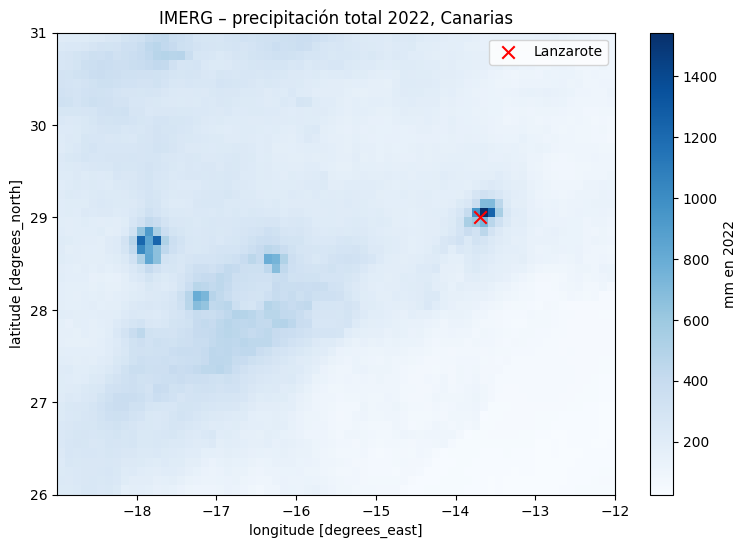

In [ ]:
FORZAR = False
ruta = f"{BRUTOS}/imerg_canarias_2022.nc"
if existe(ruta, FORZAR):
    total = xr.open_dataarray(ruta).load()
else:
    res = earthaccess.search_data(short_name="GPM_3IMERGM", version="07", temporal=("2022-01-01", "2022-12-31"))
    total = 0
    for g, f in zip(res, earthaccess.open(res)):
        fecha = fecha_granulo(g)
        with xr.open_dataset(f, group="Grid", engine="h5netcdf", decode_times=False) as ds:
            caja = ds["precipitation"].isel(time=0).sel(lat=slice(26, 31), lon=slice(-19, -12)).load()
        total = total + caja * fecha.days_in_month * 24
    total = total.transpose("lat", "lon").rename("precip_mm_2022")
    guardar_nc(total, ruta)

lz = df_pr[df_pr.sitio == "Lanzarote (España)"]
print(f"Lanzarote: meses con > 5 mm según IMERG = {(lz.mm > 5).sum()} de {len(lz)}")
total.plot(figsize=(9, 6), cmap="Blues", cbar_kwargs={"label": "mm en 2022"})
plt.scatter([-13.7], [29.0], c="red", marker="x", s=80, label="Lanzarote")
plt.legend(); plt.title("IMERG – precipitación total 2022, Canarias"); plt.show()

### 3.3 MERRA-2: series globales mensuales (descarga reanudable por año)
Solo se descargan si la climatología de la sección 3.5 no está todavía en Drive. Tarda alrededor de una hora la primera vez.

In [ ]:
def pila_mensual_cache(short_name, var, anio_ini=2014, anio_fin=2023):
    capas = []
    for anio in range(anio_ini, anio_fin + 1):
        ruta = f"{BRUTOS}/merra2_{var}_{anio}.nc"
        if not os.path.exists(ruta):
            print(f"  ⬇ {var} {anio} ...", end=" ", flush=True)
            res = earthaccess.search_data(short_name=short_name, temporal=(f"{anio}-01-01", f"{anio}-12-31"))
            meses = []
            for g, f in zip(res, earthaccess.open(res, show_progress=False)):
                fecha = fecha_granulo(g)
                if fecha.year != anio:
                    continue
                with xr.open_dataset(f, engine="h5netcdf", decode_times=False) as ds:
                    capa = ds[var].isel(time=0).load().drop_vars("time", errors="ignore")
                meses.append(capa.expand_dims(fecha=[fecha]))
            guardar_nc(xr.concat(meses, dim="fecha").sortby("fecha").rename(var), ruta)
            print("guardado")
        capas.append(xr.open_dataarray(ruta).load())
    return xr.concat(capas, dim="fecha").drop_duplicates("fecha")

FORZAR = False
if os.path.exists(f"{PROCESADOS}/clima_merra2_2014_2023.nc") and not FORZAR:
    T2M = PREC = None
    print("✔ La climatología ya está en Drive: no hace falta descargar las series globales.")
else:
    T2M = pila_mensual_cache("M2TMNXSLV", "T2M")
    PREC = pila_mensual_cache("M2TMNXFLX", "PRECTOTCORR")

✔ La climatología ya está en Drive: no hace falta descargar las series globales.


### 3.4 Constantes de MERRA-2 (tierra, hielo, elevación)

In [ ]:
FORZAR = False
ruta = f"{BRUTOS}/merra2_constantes.nc"
if existe(ruta, FORZAR):
    cte = xr.open_dataset(ruta).load()
else:
    g = earthaccess.search_data(short_name="M2C0NXASM")
    with xr.open_dataset(earthaccess.open(g[:1])[0], engine="h5netcdf", decode_times=False) as ds:
        cte = ds[["FRLAND", "FRLANDICE", "PHIS"]].isel(time=0).drop_vars("time", errors="ignore").load()
    guardar_nc(cte, ruta)

✔ desde Drive: merra2_constantes.nc


### 3.5 Climatología global 2014-2023

In [ ]:
FORZAR = False
ruta_clim = f"{PROCESADOS}/clima_merra2_2014_2023.nc"

def anadir_elevacion(c):
    elev = (cte["PHIS"] / 9.80665).astype("float32")
    c["elevacion"] = elev
    c["elevacion"].attrs = {"units": "m", "long_name": "Elevación media del píxel (PHIS/g)"}
    c["presion_aprox"] = (1013.25 * (1 - 2.25577e-5 * elev.clip(min=0)) ** 5.25588).astype("float32")
    c["presion_aprox"].attrs = {"units": "hPa", "long_name": "Presión aproximada por altitud (Marte ≈ 6 hPa)"}
    return c

if existe(ruta_clim, FORZAR):
    clim = xr.open_dataset(ruta_clim).load().drop_vars("time", errors="ignore")
    if "elevacion" not in clim:
        clim = anadir_elevacion(clim); guardar_nc(clim, ruta_clim)
else:
    T = T2M - 273.15
    fechas = pd.DatetimeIndex(PREC.fecha.values)
    dias = xr.DataArray(fechas.days_in_month, dims="fecha", coords={"fecha": PREC.fecha})
    P_mm = PREC * 86400 * dias
    clim = xr.Dataset({
        "T_media":  T.mean("fecha"),
        "T_frio":   T.groupby("fecha.month").mean().min("month"),
        "T_calido": T.groupby("fecha.month").mean().max("month"),
        "P_anual":  P_mm.sum("fecha") / fechas.year.nunique(),
        "tierra":   cte["FRLAND"] + cte["FRLANDICE"],
        "hielo":    cte["FRLANDICE"],
    }).astype("float32")
    meta = {"T_media": ("degC", "Temperatura media a 2 m, 2014-2023"),
            "T_frio": ("degC", "Temperatura media del mes más frío"),
            "T_calido": ("degC", "Temperatura media del mes más cálido"),
            "P_anual": ("mm/año", "Precipitación media anual (PRECTOTCORR)"),
            "tierra": ("1", "Fracción de tierra incl. hielo"), "hielo": ("1", "Fracción de hielo continental")}
    for v, (u, d) in meta.items():
        clim[v].attrs = {"units": u, "long_name": d}
    clim = anadir_elevacion(clim)
    clim.attrs = {"fuente": "NASA MERRA-2 (M2TMNXSLV, M2TMNXFLX, M2C0NXASM) vía earthaccess",
                  "periodo": "2014-2023", "rejilla": "0.5° lat x 0.625° lon",
                  "proyecto": "NASA Space Apps 2026 - análogos terrestres de Luna/Marte"}
    guardar_nc(clim, ruta_clim)
print(list(clim.data_vars))

✔ desde Drive: clima_merra2_2014_2023.nc
['T_media', 'T_frio', 'T_calido', 'P_anual', 'tierra', 'hielo', 'elevacion', 'presion_aprox', 'ndvi_max', 'frac_desnudo']


### 3.6 IMERG frente a MERRA-2 en los puntos de prueba

In [ ]:
ruta = f"{PROCESADOS}/merra2_analogos_2014_2023.csv"
if existe(ruta):
    m2 = pd.read_csv(ruta, parse_dates=["fecha"])
else:
    def serie_puntual(short_name, var, inicio="2014-01-01", fin="2023-12-31"):
        res = earthaccess.search_data(short_name=short_name, temporal=(inicio, fin))
        filas = []
        for g, f in zip(res, earthaccess.open(res)):
            with xr.open_dataset(f, engine="h5netcdf", decode_times=False) as ds:
                for n, (la, lo) in PUNTOS_PRUEBA.items():
                    v = float(ds[var].isel(time=0).sel(lat=la, lon=lo, method="nearest").values)
                    filas.append({"sitio": n, "fecha": fecha_granulo(g), var: v})
        return pd.DataFrame(filas)
    m2 = serie_puntual("M2TMNXSLV", "T2M").merge(serie_puntual("M2TMNXFLX", "PRECTOTCORR"), on=["sitio", "fecha"])
    m2["T_C"] = m2["T2M"] - 273.15
    m2["pr_mm"] = m2["PRECTOTCORR"] * 86400 * m2["fecha"].dt.days_in_month
    m2.to_csv(ruta, index=False)

anio = m2.fecha.dt.year
comparacion_fuentes = pd.DataFrame({
    "T_media_C":    m2.groupby("sitio")["T_C"].mean(),
    "pr_MERRA2_mm": m2.groupby(["sitio", anio])["pr_mm"].sum().groupby("sitio").mean(),
    "pr_IMERG_mm":  anual_imerg["media"],
}).round(1)
comparacion_fuentes.sort_values("pr_MERRA2_mm")

✔ desde Drive: merra2_analogos_2014_2023.csv


,T_media_C,pr_MERRA2_mm,pr_IMERG_mm
sitio,,,
Atacama (Chile),17.5,11.3,95.1
Valles Secos (Antártida),-27.2,82.8,0.1
Lanzarote (España),20.3,142.3,833.6
Isla Devon (Canadá),-15.4,322.1,150.8
Río Tinto (España),18.3,443.0,572.3
Madrid (control),14.0,480.5,536.5


### 3.7 VIIRS NDVI 2023 (vegetación)
NDVI máximo mensual de 2023 a 0.05° (~5 km) y su paso a la rejilla de MERRA-2 como **fracción de suelo desnudo** (NDVI máx < 0.15).
La primera ejecución tarda unos 10 minutos (12 meses, con caché mensual en Drive).

✔ desde Drive: ndvi_max_2023_005.nc
Rango NDVI: -0.70 a 1.00  (debe estar entre -1 y 1)


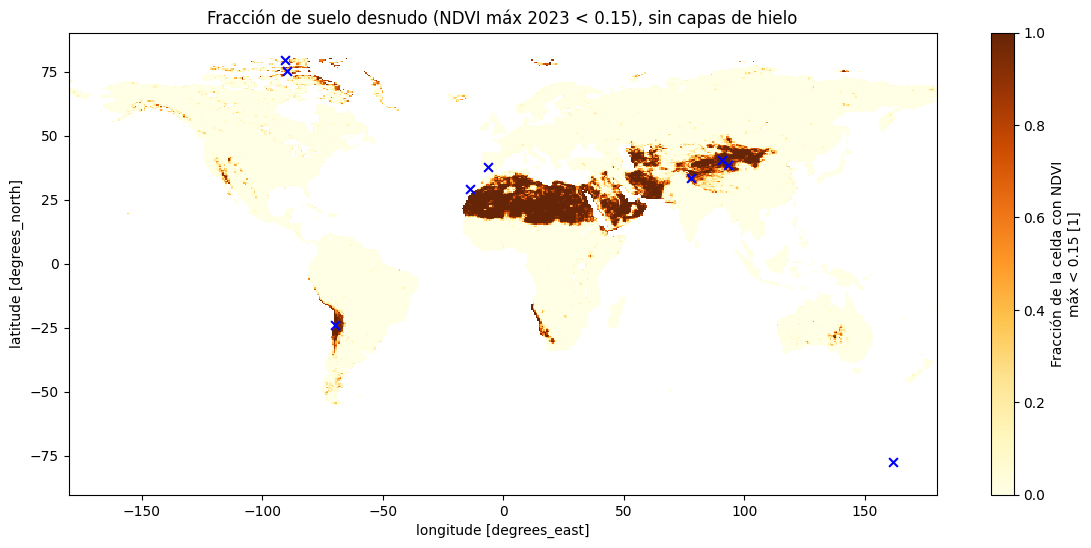

In [ ]:
ANIO_NDVI, UMBRAL_DESNUDO = 2023, 0.15
GRP = "HDFEOS/GRIDS/VIIRS_Grid_monthly_VI_CMG/Data Fields/"
VAR_NDVI = GRP + "CMG 0.05 Deg monthly NDVI"
ENC = {"ndvi": {"dtype": "int16", "scale_factor": 1e-4, "_FillValue": -32768, "zlib": True}}

def leer_ndvi(f):
    with h5py.File(f, "r") as h:
        d = h[VAR_NDVI]
        raw = d[:].astype("float32")
        a = dict(d.attrs)
        lat, lon = h[GRP + "lat"][:], h[GRP + "lon"][:]
    rellenos = np.ravel(a.get("_FillValue", [-15000])).astype(float)          # VIIRS trae varios códigos
    rango = np.ravel(a.get("valid_range", [-10000, 10000])).astype(float)
    sf = float(np.ravel(a.get("scale_factor", [10000]))[0])
    raw[np.isin(raw, rellenos) | (raw < rango[0]) | (raw > rango[-1])] = np.nan
    ndvi = raw / sf if sf > 1 else raw * sf
    return xr.DataArray(ndvi, dims=("lat", "lon"), coords={"lat": lat, "lon": lon}, name="ndvi").sortby("lat")

FORZAR = False
ruta_max = f"{PROCESADOS}/ndvi_max_{ANIO_NDVI}_005.nc"
if existe(ruta_max, FORZAR):
    ndvi_max = xr.open_dataarray(ruta_max).load()
else:
    res = earthaccess.search_data(short_name="VNP13C2", version="002",
                                  temporal=(f"{ANIO_NDVI}-01-01", f"{ANIO_NDVI}-12-31"))
    ndvi_max = None
    for g in res:
        fecha = fecha_granulo(g)
        ruta_mes = f"{BRUTOS}/ndvi_{fecha:%Y_%m}.nc"
        if not os.path.exists(ruta_mes):
            print(f"  ⬇ {fecha:%Y-%m} ...", end=" ", flush=True)
            guardar_nc(leer_ndvi(earthaccess.open([g], show_progress=False)[0]).to_dataset(), ruta_mes, ENC)
            print("guardado")
        mes = xr.open_dataarray(ruta_mes).load()
        ndvi_max = mes if ndvi_max is None else np.fmax(ndvi_max, mes)
    ndvi_max = ndvi_max.rename("ndvi")
    ndvi_max.attrs = {"long_name": f"NDVI máximo mensual {ANIO_NDVI} (VIIRS VNP13C2 v002, 0.05°)"}
    guardar_nc(ndvi_max.to_dataset(), ruta_max, ENC)
    ndvi_max = xr.open_dataarray(ruta_max).load()
print(f"Rango NDVI: {float(ndvi_max.min()):.2f} a {float(ndvi_max.max()):.2f}  (debe estar entre -1 y 1)")

if "frac_desnudo" not in clim or FORZAR:
    v = ndvi_max.transpose("lat", "lon").values
    ilat = np.clip(np.round((ndvi_max.lat.values + 90) / 0.5).astype(int), 0, clim.sizes["lat"] - 1)
    ilon = np.round((ndvi_max.lon.values + 180) / 0.625).astype(int) % clim.sizes["lon"]
    idx = (ilat[:, None] * clim.sizes["lon"] + ilon[None, :]).ravel()
    vv = v.ravel(); ok = ~np.isnan(vv); N = clim.sizes["lat"] * clim.sizes["lon"]
    n = np.bincount(idx[ok], minlength=N)
    suma = np.bincount(idx[ok], weights=vv[ok], minlength=N)
    desn = np.bincount(idx[ok], weights=(vv[ok] < UMBRAL_DESNUDO).astype(float), minlength=N)
    forma = (clim.sizes["lat"], clim.sizes["lon"])
    with np.errstate(invalid="ignore", divide="ignore"):
        clim["ndvi_max"] = (("lat", "lon"), np.where(n > 0, suma / n, np.nan).reshape(forma).astype("float32"))
        clim["frac_desnudo"] = (("lat", "lon"), np.where(n > 0, desn / n, np.nan).reshape(forma).astype("float32"))
    clim["ndvi_max"].attrs = {"units": "1", "long_name": f"NDVI máximo {ANIO_NDVI} medio en la celda (VIIRS)"}
    clim["frac_desnudo"].attrs = {"units": "1", "long_name": f"Fracción de la celda con NDVI máx < {UMBRAL_DESNUDO}"}
    guardar_nc(clim, ruta_clim)
    print("  + NDVI y fracción de suelo desnudo añadidos a la climatología")

clim.frac_desnudo.where((clim.tierra > 0.5) & (clim.hielo < 0.5)).plot(figsize=(14, 6), cmap="YlOrBr", vmin=0, vmax=1)
plt.scatter(catalogo.lon, catalogo.lat, c="blue", marker="x", s=40)
plt.title(f"Fracción de suelo desnudo (NDVI máx {ANIO_NDVI} < {UMBRAL_DESNUDO}), sin capas de hielo"); plt.show()

### 3.8 Diagnóstico del NDVI en el Ártico
Devon y Axel Heiberg dan NDVI de verano de 0.14-0.29 aunque la literatura describe Devon como "desierto polar".
La serie mensual muestra si es ruido (picos sueltos) o una señal estacional real.

In [ ]:
puntos_artico = {"Devon (HMP)": (75.43, -89.87), "Axel Heiberg (Gypsum Hill)": (79.40, -90.73),
                 "Atacama (comparación)": (-24.1, -70.0)}
filas = {}
for nombre, (la, lo) in puntos_artico.items():
    serie = []
    for m in range(1, 13):
        ruta_mes = f"{BRUTOS}/ndvi_{ANIO_NDVI}_{m:02d}.nc"
        if not os.path.exists(ruta_mes):
            serie.append(np.nan); continue
        with xr.open_dataarray(ruta_mes) as da:
            serie.append(round(float(da.sel(lat=la, lon=lo, method="nearest")), 2))
    filas[nombre] = serie
pd.DataFrame(filas, index=range(1, 13)).T

,1,2,3,4,5,6,7,8,9,10,11,12
Devon (HMP),NaN,-0.04,-0.02,-0.02,-0.02,0.14,0.22,0.22,0.21,-0.03,-0.12,NaN
Axel Heiberg (Gypsum Hill),NaN,-0.12,-0.02,-0.02,-0.02,0.23,0.29,0.26,0.26,-0.07,NaN,NaN
Atacama (comparación),0.1,0.10,0.10,0.10,0.10,0.10,0.10,0.10,0.10,0.10,0.10,0.1


## 4. Exploración de variables
Máscara de análisis: celdas con más del 50 % de tierra y menos del 50 % de hielo.

In [ ]:
VARS = ["T_media", "T_frio", "T_calido", "P_anual", "elevacion", "presion_aprox", "ndvi_max", "frac_desnudo"]
validos = (clim.tierra > 0.5) & (clim.hielo < 0.5)
tabla_tierra = clim[VARS].where(validos).to_dataframe()[VARS].dropna()
print(f"Celdas de tierra sin hielo con todas las variables: {len(tabla_tierra):,}")
tabla_tierra.describe(percentiles=[0.01, 0.5, 0.99]).T.round(2)

Celdas de tierra sin hielo con todas las variables: 46,444


,count,mean,std,min,1%,50%,99%,max
T_media,46444.0,10.49,13.49,-17.87,-13.99,11.35,28.82,33.53
T_frio,46444.0,-1.46,19.54,-41.36,-36.68,-0.04,26.16,29.07
T_calido,46444.0,22.28,8.20,-0.30,4.98,23.36,37.37,40.62
P_anual,46444.0,764.48,602.80,0.38,11.84,635.22,2913.12,6450.14
elevacion,46444.0,612.98,777.46,-51.89,10.79,358.98,4533.21,5538.51
presion_aprox,46444.0,944.88,78.71,502.44,574.76,970.86,1011.95,1013.25
ndvi_max,46444.0,0.59,0.25,-0.10,0.08,0.68,0.88,0.91
frac_desnudo,46444.0,0.11,0.28,0.00,0.00,0.00,1.00,1.00


### 4.1 Distribuciones: análogos y controles sobre el conjunto de la Tierra
Histograma de todas las celdas de tierra (gris), análogos del catálogo (azul) y controles (naranja).
Una variable es útil si los análogos caen en un extremo y los controles en el centro.

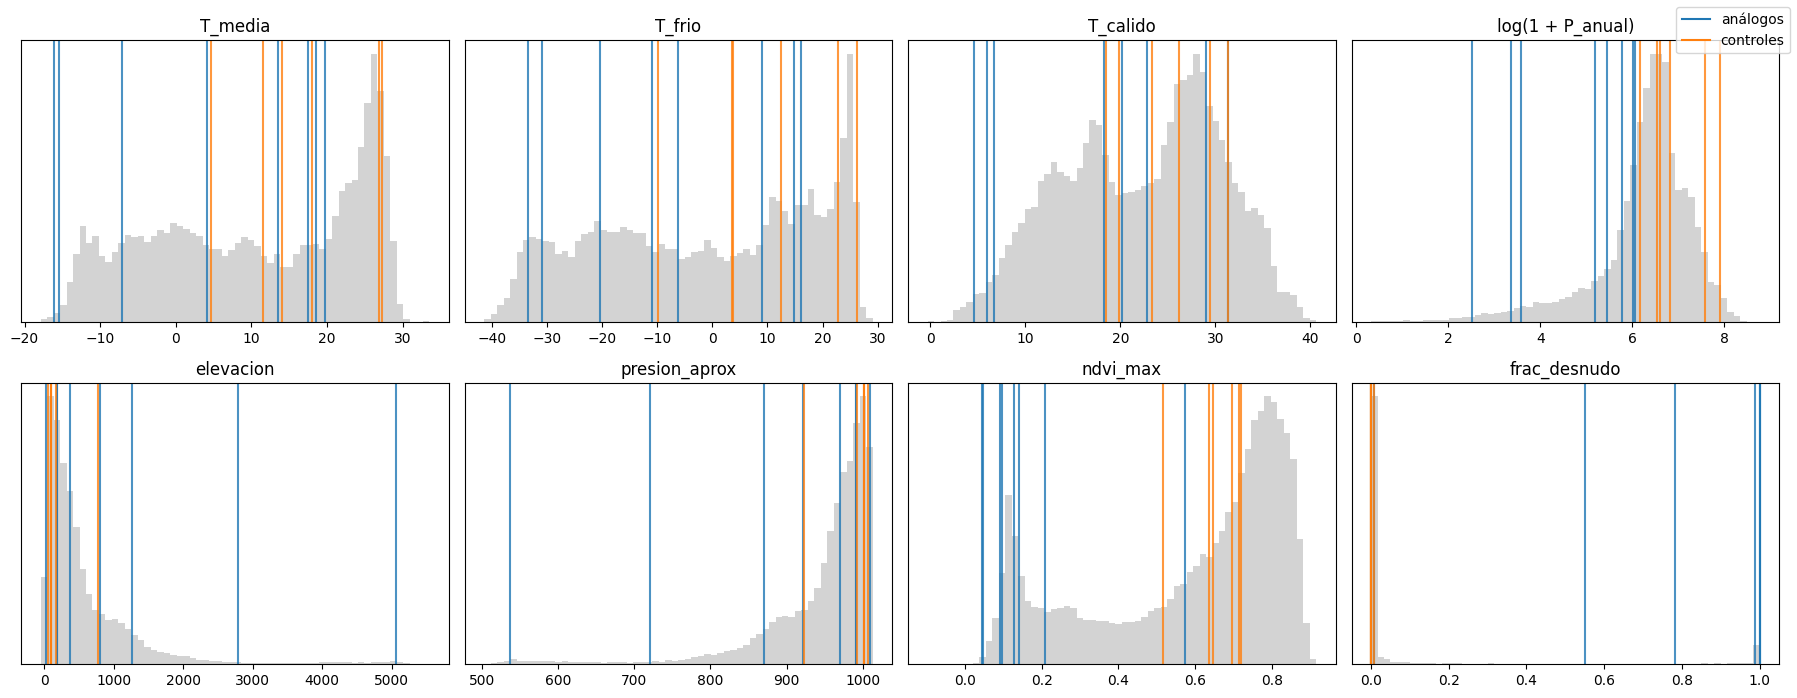

In [ ]:
def valores_en(puntos):
    filas = []
    for nombre, (la, lo) in puntos.items():
        fila = {"punto": nombre}
        for v in VARS:
            fila[v], _ = valor_cercano(clim[v].where(validos), la, lo)
        filas.append(fila)
    return pd.DataFrame(filas).set_index("punto")

val_analogos = valores_en({r.nombre: (r.lat, r.lon) for r in catalogo.itertuples()})
val_controles = valores_en(CONTROLES)

fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, v in zip(axes.ravel(), VARS):
    datos = np.log1p(tabla_tierra[v]) if v == "P_anual" else tabla_tierra[v]
    ax.hist(datos, bins=60, color="lightgrey")
    for valores, color in [(val_analogos[v], "tab:blue"), (val_controles[v], "tab:orange")]:
        for x in valores.dropna():
            ax.axvline(np.log1p(x) if v == "P_anual" else x, color=color, lw=1.5, alpha=0.8)
    ax.set_title("log(1 + P_anual)" if v == "P_anual" else v); ax.set_yticks([])
fig.legend(handles=[plt.Line2D([], [], color="tab:blue", label="análogos"),
                    plt.Line2D([], [], color="tab:orange", label="controles")], loc="upper right")
plt.tight_layout(); plt.show()

### 4.2 Valores en cada análogo y control

In [ ]:
pd.concat([val_analogos.assign(tipo="análogo"), val_controles.assign(tipo="control")]).round(2)

,T_media,T_frio,T_calido,P_anual,elevacion,presion_aprox,ndvi_max,frac_desnudo,tipo
punto,,,,,,,,,
Cuenca de Qaidam occidental (Lenghu),4.16,-11.00,18.23,28.24,2784.05,720.55,0.05,1.00,análogo
Isla Axel Heiberg (Gypsum Hill / M.A.R.S.),-16.10,-30.82,4.56,234.62,367.40,969.88,0.14,0.55,análogo
Isla Devon (Haughton-Mars Project),-15.39,-33.38,6.00,322.15,188.23,990.84,0.21,0.01,análogo
"Desierto de Atacama, núcleo hiperárido (ARADS)",17.50,14.85,20.16,11.33,1261.44,870.61,0.09,1.00,análogo
Valles Secos de McMurdo,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,análogo
Lanzarote (ESA PANGAEA),19.78,16.03,22.82,179.99,25.71,1010.16,0.10,0.99,análogo
Río Tinto (MARTE),18.50,9.10,29.06,426.09,187.84,990.89,0.57,0.00,análogo
"Tso Kar, Ladakh (ISRO HOPE)",-7.08,-20.41,6.68,409.13,5060.15,535.87,0.13,0.78,análogo
Lop Nur (cuenca del Tarim),13.52,-6.24,31.29,35.01,795.95,921.21,0.04,1.00,análogo


### 4.3 Correlación entre variables (Spearman)
Variables muy correlacionadas aportan información repetida al índice (por ejemplo, NDVI y precipitación).

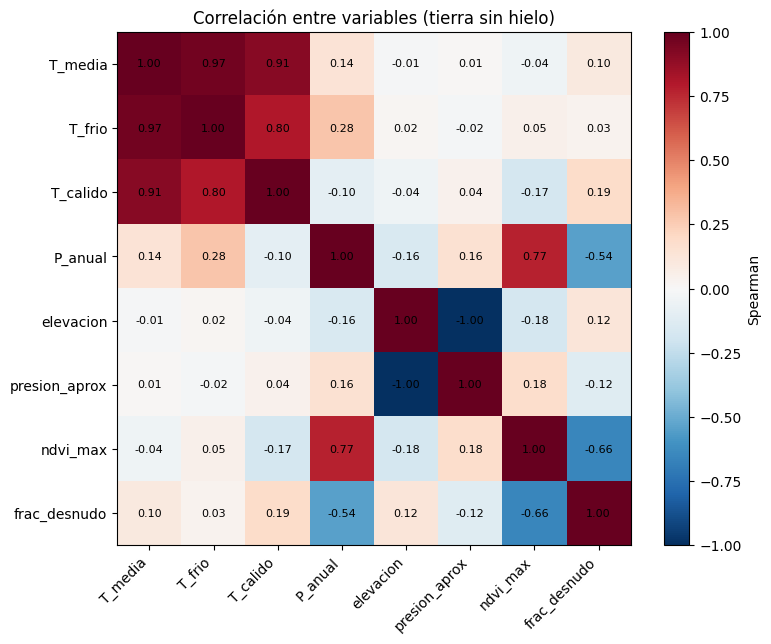

In [ ]:
corr = tabla_tierra.corr(method="spearman")
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(VARS)), VARS, rotation=45, ha="right"); ax.set_yticks(range(len(VARS)), VARS)
for i in range(len(VARS)):
    for j in range(len(VARS)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(im, label="Spearman"); plt.title("Correlación entre variables (tierra sin hielo)")
plt.tight_layout(); plt.show()

## 5. Índice por perfiles
- **Zonas** (cada celda pertenece como mucho a un perfil):
  - *Marte polar*: |lat| ≥ 60° y mes más cálido < 10 °C (criterio polar de Köppen)
  - *Marte altura*: |lat| < 60° y elevación ≥ 2500 m
  - *Marte árido*: |lat| < 60° y elevación < 2500 m
- **Componentes** (0-1, mayor = más parecido a Marte), normalizados entre los percentiles 1 y 99 de la tierra sin hielo:
  `frio` (T media invertida), `verano_frio` (T del mes cálido invertida), `seco` (log P anual invertida),
  `presion` (presión por altitud invertida), `amplitud` (T cálido − T frío), `sin_vegetacion` (NDVI invertido, solo v1.2),
  `desnudo` (fracción de suelo desnudo, sin normalizar).
- **Salida**: percentil de cada celda **dentro de su zona** (0-100).
- Se calculan las tres versiones para poder compararlas; la activa es la v1.3.

{'marte_polar': 2881, 'marte_altura': 1458, 'marte_arido': 35168} celdas por zona


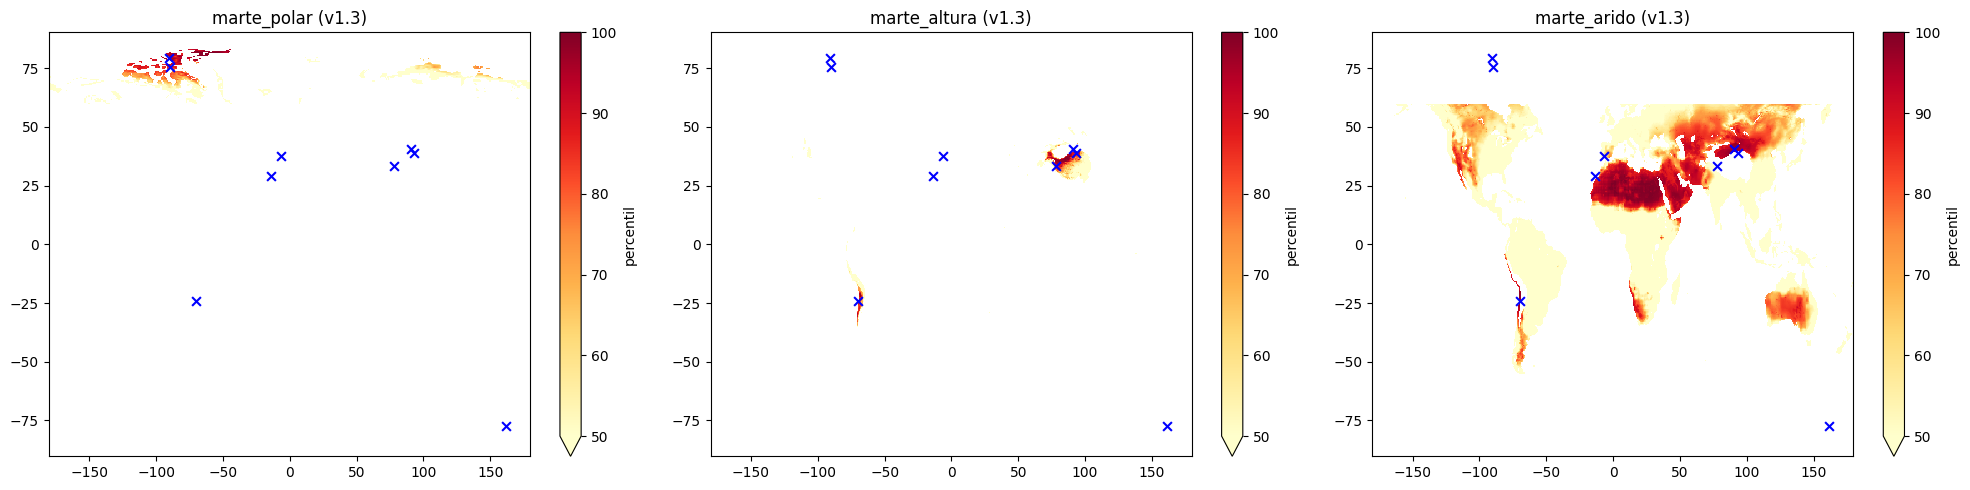

In [ ]:
LAT_POLAR, UMBRAL_ALTURA_M = 60, 2500
POLAR = {"frio": 0.45, "verano_frio": 0.20, "seco": 0.35}
VERSIONES = {
    "v1.1": {"marte_polar": POLAR,
             "marte_altura": {"frio": 0.30, "seco": 0.40, "presion": 0.30},
             "marte_arido":  {"seco": 0.80, "amplitud": 0.20}},
    "v1.2": {"marte_polar": POLAR,
             "marte_altura": {"frio": 0.25, "seco": 0.35, "presion": 0.25, "sin_vegetacion": 0.15},
             "marte_arido":  {"seco": 0.65, "amplitud": 0.15, "sin_vegetacion": 0.20}},
    "v1.3": {"marte_polar": POLAR,
             "marte_altura": {"frio": 0.25, "seco": 0.35, "presion": 0.25, "desnudo": 0.15},
             "marte_arido":  {"seco": 0.65, "amplitud": 0.15, "desnudo": 0.20}},
}
VERSION_ACTIVA = "v1.3"
nombres = list(VERSIONES[VERSION_ACTIVA])

abs_lat = np.abs(clim.lat)
ZONAS = {
    "marte_polar":  validos & (abs_lat >= LAT_POLAR) & (clim.T_calido < 10),
    "marte_altura": validos & (abs_lat <  LAT_POLAR) & (clim.elevacion >= UMBRAL_ALTURA_M),
    "marte_arido":  validos & (abs_lat <  LAT_POLAR) & (clim.elevacion <  UMBRAL_ALTURA_M),
}

def normalizar(x, invertir=False):
    x = x.where(validos)
    lo, hi = float(x.quantile(0.01)), float(x.quantile(0.99))
    s = ((x - lo) / (hi - lo)).clip(0, 1)
    return 1 - s if invertir else s

componentes = xr.Dataset({
    "frio":           normalizar(clim.T_media, invertir=True),
    "verano_frio":    normalizar(clim.T_calido, invertir=True),
    "seco":           normalizar(np.log1p(clim.P_anual), invertir=True),
    "presion":        normalizar(clim.presion_aprox, invertir=True),
    "amplitud":       normalizar(clim.T_calido - clim.T_frio),
    "sin_vegetacion": normalizar(clim.ndvi_max, invertir=True),
    "desnudo":        clim.frac_desnudo.where(validos),
})

def a_percentil(da):
    v = da.values; m = ~np.isnan(v)
    out = np.full(v.shape, np.nan, dtype="float32")
    out[m] = pd.Series(v[m]).rank(pct=True).values * 100
    return da.copy(data=out)

def calcular_indices(perfiles, version):
    ind = xr.Dataset()
    perfil_id = xr.zeros_like(clim.T_media, dtype="int8")
    pct_asignado = xr.full_like(clim.T_media, np.nan)
    for k, perfil in enumerate(nombres, start=1):
        pesos = perfiles[perfil]
        assert abs(sum(pesos.values()) - 1) < 1e-9, f"{version}: los pesos de {perfil} no suman 1"
        bruto = sum(p * componentes[c] for c, p in pesos.items()).where(ZONAS[perfil])
        ind[perfil] = bruto.astype("float32")
        ind[perfil].attrs = {"long_name": f"Índice {perfil} {version}", "pesos": json.dumps(pesos)}
        ind[f"{perfil}_pct"] = a_percentil(bruto)
        ind[f"{perfil}_pct"].attrs = {"units": "percentil", "long_name": f"Percentil dentro de la zona {perfil}"}
        perfil_id = perfil_id.where(~ZONAS[perfil], k)
        pct_asignado = pct_asignado.where(~ZONAS[perfil], ind[f"{perfil}_pct"])
    ind["perfil_id"] = perfil_id
    ind["perfil_id"].attrs = {"codigos": json.dumps({0: "ninguno", **{k: p for k, p in enumerate(nombres, 1)}})}
    ind["pct_asignado"] = pct_asignado.astype("float32")
    ind.attrs = {"version": version, "base": "clima_merra2_2014_2023.nc",
                 "zonas": f"polar: |lat|>={LAT_POLAR} y T_calido<10; altura: elev>={UMBRAL_ALTURA_M} m; árido: resto"}
    return ind

TODOS = {}
for ver, perfiles in VERSIONES.items():
    TODOS[ver] = calcular_indices(perfiles, ver)
    guardar_nc(TODOS[ver], f"{carpeta_version(ver)}/indices_perfiles_{ver}.nc")
indices = TODOS[VERSION_ACTIVA]
print({p: int(ZONAS[p].sum()) for p in nombres}, "celdas por zona")

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, perfil in zip(axes, nombres):
    indices[f"{perfil}_pct"].plot(ax=ax, cmap="YlOrRd", vmin=50, vmax=100, cbar_kwargs={"label": "percentil"})
    ax.scatter(catalogo.lon, catalogo.lat, c="blue", marker="x", s=40)
    ax.set_title(f"{perfil} ({VERSION_ACTIVA})"); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()

## 6. Validación
Para cada análogo: ¿cae en el perfil esperado y con qué percentil? Para cada control: ¿queda bajo?
- **Separación de medianas**: mediana de los análogos bien asignados − mediana de los controles.
- **Peor análogo − mejor control**: si es positiva, hasta el análogo peor puntuado supera al control más alto.
Criterio para aceptar una versión: mayor separación, sin que baje ningún análogo verificado.

In [ ]:
def perfil_esperado(texto):
    t = str(texto).lower()
    if "polar" in t:                  return "marte_polar"
    if "altura" in t or "frío" in t:  return "marte_altura"
    if "árido" in t:                  return "marte_arido"
    return "—"

puntos = [(r.nombre, r.lat, r.lon, perfil_esperado(r.perfil)) for r in catalogo.itertuples()]
puntos += [(f"{n} (control)", la, lo, "control") for n, (la, lo) in CONTROLES.items()]

def validar(ind):
    filas = []
    for nombre, la, lo, esperado in puntos:
        v, pos = valor_cercano(ind["pct_asignado"], la, lo)
        asignado = "sin píxel válido" if pos is None else nombres[int(ind["perfil_id"].sel(lat=pos[0], lon=pos[1])) - 1]
        filas.append({"punto": nombre, "esperado": esperado, "asignado": asignado,
                      "coincide": "✔" if asignado == esperado else ("" if esperado in ("—", "control") else "✘"),
                      "percentil": round(v, 1) if pos else np.nan,
                      "pixel": f"{pos[0]:.1f}, {pos[1]:.2f}" if pos else ""})
    return pd.DataFrame(filas)

tabla, resumen = {}, []
for ver, ind in TODOS.items():
    df = validar(ind)
    df.to_csv(f"{carpeta_version(ver)}/validacion_perfiles_{ver}.csv", index=False)
    tabla[ver] = df.set_index("punto").percentil
    an = df[df.coincide == "✔"].percentil
    ct = df[df.esperado == "control"].percentil
    resumen.append({"version": ver, "mediana_analogos": round(an.median(), 1), "mediana_controles": round(ct.median(), 1),
                    "max_control": round(ct.max(), 1), "separacion_medianas": round(an.median() - ct.median(), 1),
                    "peor_analogo_menos_mejor_control": round(an.min() - ct.max(), 1)})
validacion = validar(indices)
resumen = pd.DataFrame(resumen)
resumen.to_csv(f"{RESULTADOS}/comparacion_versiones.csv", index=False)

display(validacion)
display(resumen)
display(pd.DataFrame(tabla))

,punto,esperado,asignado,coincide,percentil,pixel
0,Cuenca de Qaidam occidental (Lenghu),marte_altura,marte_altura,✔,90.8,"38.5, 93.12"
1,Isla Axel Heiberg (Gypsum Hill / M.A.R.S.),marte_polar,marte_polar,✔,94.9,"79.0, -91.88"
2,Isla Devon (Haughton-Mars Project),marte_polar,marte_polar,✔,85.0,"75.5, -90.00"
3,"Desierto de Atacama, núcleo hiperárido (ARADS)",marte_arido,marte_arido,✔,98.0,"-24.0, -70.00"
4,Valles Secos de McMurdo,marte_polar,sin píxel válido,✘,NaN,
5,Lanzarote (ESA PANGAEA),—,marte_arido,,87.5,"28.0, -12.50"
6,Río Tinto (MARTE),—,marte_arido,,60.1,"37.5, -6.25"
7,"Tso Kar, Ladakh (ISRO HOPE)",marte_altura,marte_altura,✔,82.3,"33.5, 78.12"
8,Lop Nur (cuenca del Tarim),marte_arido,marte_arido,✔,97.4,"40.5, 90.62"
9,Madrid (control),control,marte_arido,,58.0,"40.5, -3.75"


,version,mediana_analogos,mediana_controles,max_control,separacion_medianas,peor_analogo_menos_mejor_control
0,v1.1,90.0,34.9,57.9,55.1,21.4
1,v1.2,90.4,38.3,65.9,52.1,13.4
2,v1.3,92.8,35.0,58.0,57.9,24.3


,v1.1,v1.2,v1.3
punto,,,
Cuenca de Qaidam occidental (Lenghu),83.2,85.9,90.8
Isla Axel Heiberg (Gypsum Hill / M.A.R.S.),94.9,94.9,94.9
Isla Devon (Haughton-Mars Project),85.0,85.0,85.0
"Desierto de Atacama, núcleo hiperárido (ARADS)",97.7,97.9,98.0
Valles Secos de McMurdo,NaN,NaN,NaN
Lanzarote (ESA PANGAEA),76.5,82.9,87.5
Río Tinto (MARTE),59.8,64.9,60.1
"Tso Kar, Ladakh (ISRO HOPE)",79.3,79.3,82.3
Lop Nur (cuenca del Tarim),97.2,97.3,97.4


## 7. Regiones candidatas
Celdas por encima del percentil 95 de su perfil, agrupadas en regiones contiguas (8 vecinos).
Una región "contiene" un análogo si algún análogo del catálogo está a ≤ 100 km de alguna de sus celdas.
Los nombres se obtienen de OpenStreetMap (Nominatim) con caché en Drive.

In [ ]:
from geopy.geocoders import Nominatim
from geopy.extra.rate_limiter import RateLimiter
logging.getLogger("geopy").setLevel(logging.ERROR)
logging.getLogger("urllib3").setLevel(logging.ERROR)

reverse = RateLimiter(Nominatim(user_agent="space-apps-2026-analogos", timeout=10).reverse,
                      min_delay_seconds=1.1, max_retries=2, error_wait_seconds=5, swallow_exceptions=False)

def _cache_csv(ruta, columnas):
    return (pd.read_csv(ruta, keep_default_na=False).set_index("clave")[columnas].to_dict("index")
            if os.path.exists(ruta) else {})

ruta_geo, ruta_pais = f"{CACHE_API}/geocodificacion.csv", f"{CACHE_API}/geo_pais.csv"
geo_cache = {k: v["region"] for k, v in _cache_csv(ruta_geo, ["region"]).items()}
pais_cache = _cache_csv(ruta_pais, ["cc", "pais"])

def nombre_region(lat, lon):
    clave = f"{lat:.2f},{lon:.2f}"
    if clave in geo_cache:
        return geo_cache[clave]
    try:
        loc = reverse((lat, lon), language="es", zoom=5)
    except Exception:
        return "error de geocodificación"
    if loc is None:
        region = "sin resultado (mar/hielo/remoto)"
    else:
        a = loc.raw.get("address", {})
        partes = [a.get("state") or a.get("region") or a.get("county"), a.get("country")]
        region = ", ".join(p for p in partes if p) or loc.address
    geo_cache[clave] = region
    pd.DataFrame({"clave": list(geo_cache), "region": list(geo_cache.values())}).to_csv(ruta_geo, index=False)
    return region

def info_pais(lat, lon):
    clave = f"{lat:.2f},{lon:.2f}"
    if clave in pais_cache:
        return pais_cache[clave]["cc"], pais_cache[clave]["pais"]
    try:
        loc = reverse((lat, lon), language="es", zoom=3)
    except Exception:
        return "", ""
    a = loc.raw.get("address", {}) if loc else {}
    pais_cache[clave] = {"cc": a.get("country_code", "").upper(), "pais": a.get("country", "")}
    pd.DataFrame([{"clave": k, **v} for k, v in pais_cache.items()]).to_csv(ruta_pais, index=False)
    return pais_cache[clave]["cc"], pais_cache[clave]["pais"]

def es_latino(txt):
    return all(ord(ch) < 0x250 or not ch.isalpha() for ch in txt)

def region_legible(lat, lon):
    txt = nombre_region(lat, lon)
    partes = [p for p in txt.split(", ") if es_latino(p)]
    if txt.startswith(("sin resultado", "error")) or not partes:
        return info_pais(lat, lon)[1] or "zona remota / fronteriza (sin país en OSM)"
    return ", ".join(partes)


=== marte_polar: 8 regiones (celdas ≥ p95 contiguas) ===


rango,region,pais_iso,percentil_max,area_km2,T_media,P_anual,elevacion,frac_desnudo,analogo_conocido,analogo_mas_cercano,distancia_km,fuente
1,Groenlandia,GL,100.00,60300,-16.340000,120.17,507.970001,NaN,No,Isla Axel Heiberg (Gypsum Hill / M.A.R.S.),388,
2,"Nunavut, Canadá",CA,99.06,2700,-15.670000,106.45,221.229996,0.04,No,Isla Axel Heiberg (Gypsum Hill / M.A.R.S.),165,
3,"Nunavut, Canadá",CA,98.72,14800,-15.200000,117.87,328.220001,0.00,Sí,Isla Axel Heiberg (Gypsum Hill / M.A.R.S.),42,https://doi.org/10.3389/fmicb.2017.02527
4,"Nunavut, Canadá",CA,97.88,1300,-14.760000,180.69,389.709991,0.96,No,Isla Axel Heiberg (Gypsum Hill / M.A.R.S.),379,
5,Groenlandia,GL,96.77,1500,-14.080000,182.63,435.000000,0.55,No,Isla Axel Heiberg (Gypsum Hill / M.A.R.S.),483,
6,Groenlandia,GL,96.67,1500,-15.400000,199.13,585.049988,0.25,No,Isla Axel Heiberg (Gypsum Hill / M.A.R.S.),438,
7,"Nunavut, Canadá",CA,96.53,1500,-16.459999,194.03,548.679993,0.22,No,Isla Axel Heiberg (Gypsum Hill / M.A.R.S.),202,
8,"Nunavut, Canadá",CA,96.36,2200,-15.010000,203.21,171.169998,0.12,Sí,Isla Axel Heiberg (Gypsum Hill / M.A.R.S.),58,https://doi.org/10.3389/fmicb.2017.02527



=== marte_altura: 3 regiones (celdas ≥ p95 contiguas) ===


rango,region,pais_iso,percentil_max,area_km2,T_media,P_anual,elevacion,frac_desnudo,analogo_conocido,analogo_mas_cercano,distancia_km,fuente
1,"Sinkiang, China",CN,100.00,212600,-6.23,30.71,4735.939941,0.99,No,"Tso Kar, Ladakh (ISRO HOPE)",184,
2,"Región de Antofagasta, Chile",CL,98.77,10800,4.76,16.32,4301.779785,0.89,No,"Desierto de Atacama, núcleo hiperárido (ARADS)",302,
3,"Provincia de Alto Badajshán, Tayikistán",TJ,95.95,6000,-6.26,118.03,4443.160156,0.99,No,"Tso Kar, Ladakh (ISRO HOPE)",693,



=== marte_arido: 10 regiones (celdas ≥ p95 contiguas) ===


rango,region,pais_iso,percentil_max,area_km2,T_media,P_anual,elevacion,frac_desnudo,analogo_conocido,analogo_mas_cercano,distancia_km,fuente
1,Argelia,DZ,100.00,4830600,27.639999,9.48,165.589996,1.00,No,Lanzarote (ESA PANGAEA),595,
2,"Provincia de Riad, Arabia Saudita",SA,98.55,598600,28.650000,14.32,402.670013,1.00,No,"Tso Kar, Ladakh (ISRO HOPE)",2602,
3,"Región de Antofagasta, Chile",CL,98.09,89100,15.870000,10.27,1893.800049,1.00,Sí,"Desierto de Atacama, núcleo hiperárido (ARADS)",11,https://astrobiology.nasa.gov/news/nasa-tests-life-detection-drill-in-the-atacama-desert/
4,"Sinkiang, China",CN,98.01,451400,13.220000,26.28,985.580017,0.97,Pendiente,Lop Nur (cuenca del Tarim),16,https://doi.org/10.1029/2018JE005719
5,"Gobernación de Shabwah, Yemen",YE,97.19,26100,26.500000,19.15,1048.280029,0.98,No,"Tso Kar, Ladakh (ISRO HOPE)",3664,
6,"Provincia Oriental, Arabia Saudita",SA,96.95,41500,27.010000,26.05,191.210007,0.94,No,"Tso Kar, Ladakh (ISRO HOPE)",2868,
7,"Gobernación de Mutana, Irak",IQ,96.76,13500,25.200001,20.13,266.359985,0.72,No,"Tso Kar, Ladakh (ISRO HOPE)",2915,
8,"Al Wahat, Libia",LY,96.25,6800,21.360001,31.64,223.149994,1.00,No,Río Tinto (MARTE),2611,
9,"Mongolia Interior, China",CN,96.10,34800,10.840000,54.14,960.510010,1.00,No,Cuenca de Qaidam occidental (Lenghu),649,
10,"Dajla-Río de Oro, Marruecos",EH,95.71,18000,26.889999,34.24,194.679993,1.00,No,Lanzarote (ESA PANGAEA),834,


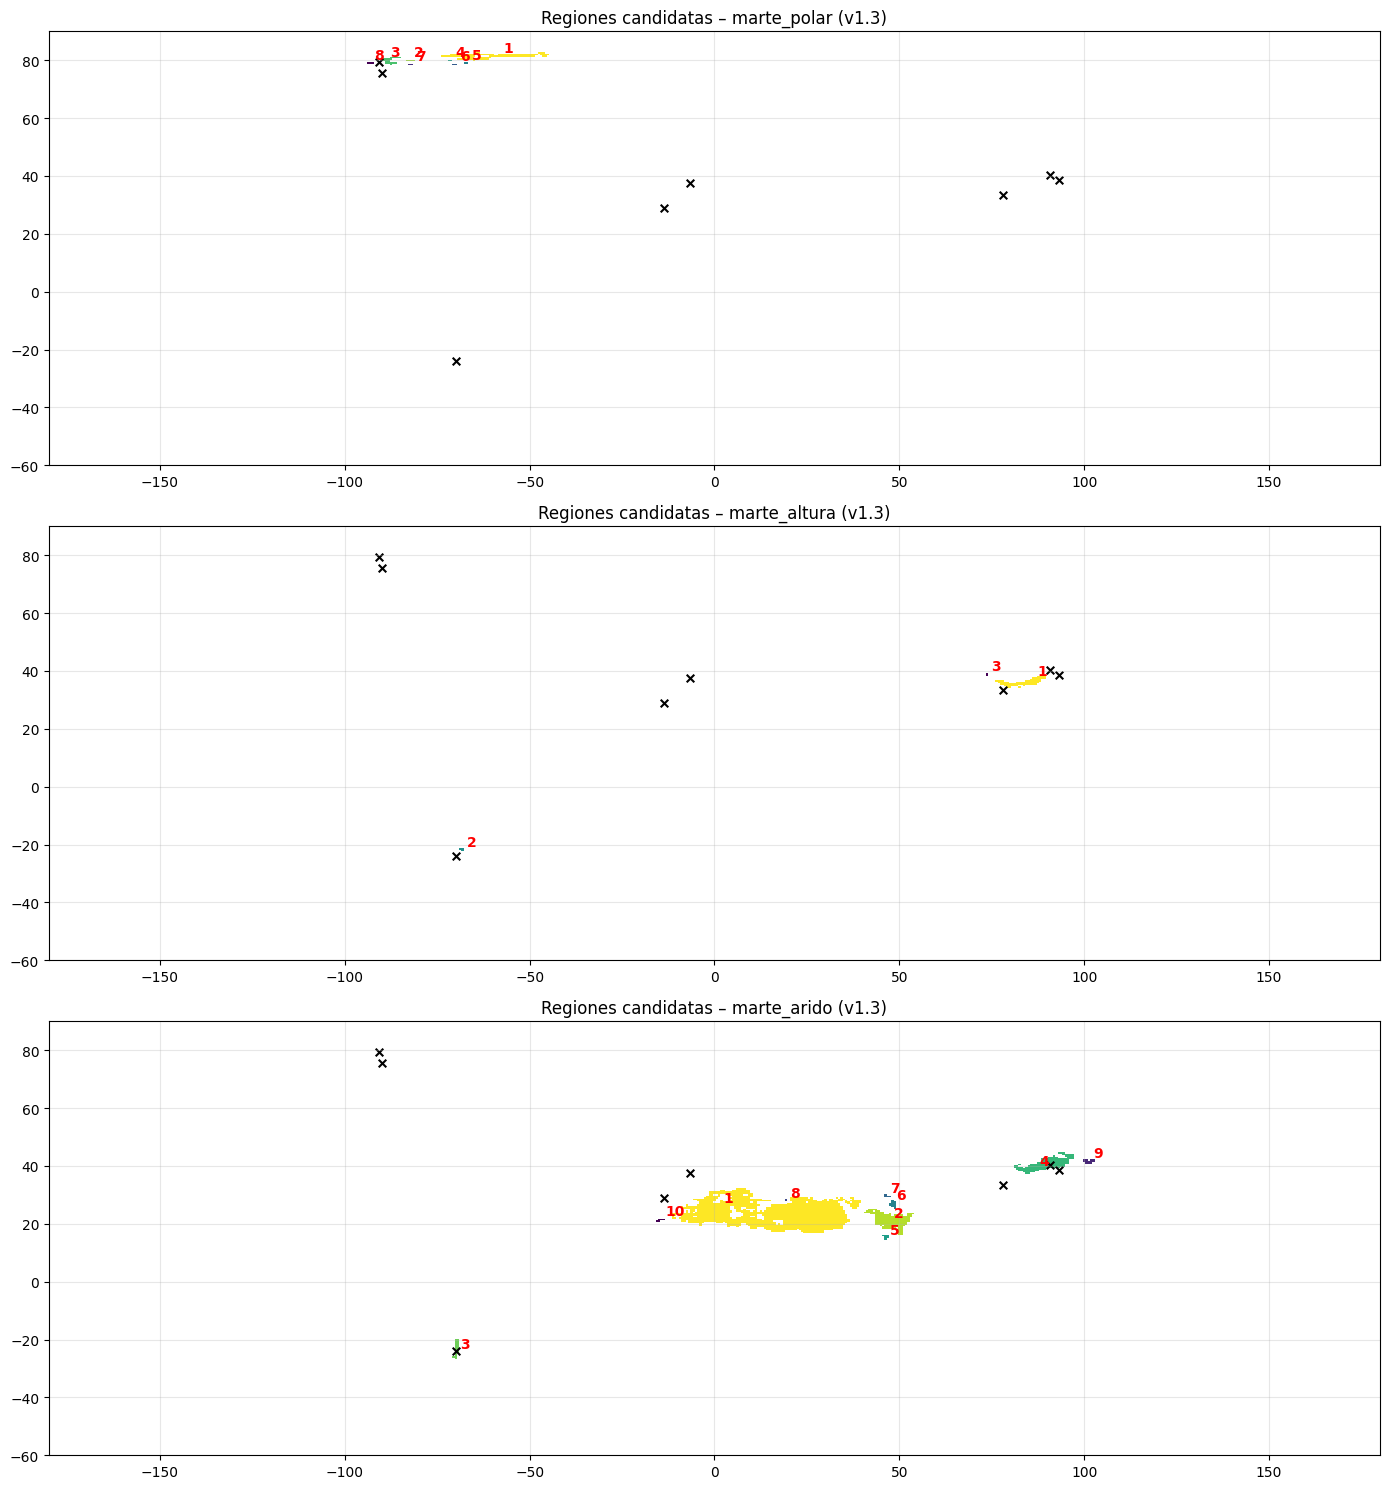

In [ ]:
UMBRAL_PCT, MIN_PIXELES, N_REGIONES, RADIO_REGION_KM = 95, 2, 10, 100
KM_GRADO = 111.32

def regiones_candidatas(pct, umbral=UMBRAL_PCT, n_max=N_REGIONES):
    pct = pct.transpose("lat", "lon")
    v, lats, lons = pct.values, pct.lat.values, pct.lon.values
    LAT2, LON2 = np.meshgrid(lats, lons, indexing="ij")
    dlat, dlon = abs(lats[1] - lats[0]), abs(lons[1] - lons[0])
    etiquetas, n = ndimage.label(np.nan_to_num(v, nan=0) >= umbral, structure=np.ones((3, 3)))
    filas = []
    for k in range(1, n + 1):
        m = etiquetas == k
        if m.sum() < MIN_PIXELES:
            continue
        vals, la_px, lo_px = v[m], LAT2[m], LON2[m]
        i = int(np.argmax(vals))
        area = np.sum(dlat * KM_GRADO * dlon * KM_GRADO * np.cos(np.radians(la_px)))
        d_cat = [haversine_km(a.lat, a.lon, la_px, lo_px).min() for a in catalogo.itertuples()]
        j = int(np.argmin(d_cat)); a = catalogo.iloc[j]
        estado = ("Sí" if a.verificacion == "verificada" else "Pendiente") if d_cat[j] <= RADIO_REGION_KM else "No"
        filas.append({"region_id": k, "lat": float(la_px[i]), "lon": float(lo_px[i]),
                      "percentil_max": round(float(vals.max()), 2), "percentil_medio": round(float(vals.mean()), 1),
                      "n_celdas": int(m.sum()), "area_km2": int(round(area, -2)),
                      "analogo_mas_cercano": a.nombre, "distancia_km": round(float(d_cat[j])),
                      "analogo_conocido": estado,
                      "fuente": a.url if estado != "No" else "", "fuente_2": a.url_2 if estado != "No" else ""})
    if not filas:
        return pd.DataFrame(), etiquetas, lats, lons
    reg = (pd.DataFrame(filas).sort_values(["percentil_max", "area_km2"], ascending=False)
             .head(n_max).reset_index(drop=True))
    reg.insert(0, "rango", range(1, len(reg) + 1))
    return reg, etiquetas, lats, lons

resultados = {}
for perfil in nombres:
    reg, etiquetas, lats, lons = regiones_candidatas(indices[f"{perfil}_pct"])
    if len(reg):
        extra = (clim[["T_media", "P_anual", "elevacion", "frac_desnudo"]]
                 .sel(lat=xr.DataArray(reg.lat.values), lon=xr.DataArray(reg.lon.values), method="nearest")
                 .to_dataframe().reset_index(drop=True)[["T_media", "P_anual", "elevacion", "frac_desnudo"]].round(2))
        reg = pd.concat([reg, extra], axis=1)
        reg["pais_iso"] = [info_pais(la, lo)[0] for la, lo in zip(reg.lat, reg.lon)]
        reg["region"] = [region_legible(la, lo) for la, lo in zip(reg.lat, reg.lon)]
    reg.to_csv(f"{carpeta_version(VERSION_ACTIVA)}/regiones_{perfil}_{VERSION_ACTIVA}.csv", index=False)
    resultados[perfil] = (reg, etiquetas, lats, lons)
    print(f"\n=== {perfil}: {len(reg)} regiones (celdas ≥ p{UMBRAL_PCT} contiguas) ===")
    if len(reg):
        display(HTML(reg[["rango", "region", "pais_iso", "percentil_max", "area_km2", "T_media", "P_anual",
                          "elevacion", "frac_desnudo", "analogo_conocido", "analogo_mas_cercano",
                          "distancia_km", "fuente"]].to_html(render_links=True, escape=False, index=False)))

fig, axes = plt.subplots(3, 1, figsize=(14, 15))
for ax, (perfil, (reg, etiquetas, lats, lons)) in zip(axes, resultados.items()):
    rango = np.full(etiquetas.shape, np.nan)
    for r in reg.itertuples():
        rango[etiquetas == r.region_id] = r.rango
        ax.annotate(str(r.rango), (r.lon, r.lat), fontsize=10, fontweight="bold", color="red",
                    xytext=(3, 3), textcoords="offset points")
    ax.pcolormesh(lons, lats, rango, cmap="viridis_r", shading="auto")
    ax.scatter(catalogo.lon, catalogo.lat, c="black", marker="x", s=30)
    ax.set_xlim(-180, 180); ax.set_ylim(-60, 90); ax.grid(alpha=0.3)
    ax.set_title(f"Regiones candidatas – {perfil} ({VERSION_ACTIVA})")
plt.tight_layout(); plt.show()

## 8. Sensibilidad al umbral
¿Cuántos análogos recoge cada perfil según el umbral elegido (p90, p95, p97.5)?

In [ ]:
filas = []
for u in [90, 95, 97.5]:
    for perfil in nombres:
        reg, *_ = regiones_candidatas(indices[f"{perfil}_pct"], umbral=u, n_max=10_000)
        capturados = validacion[(validacion.asignado == perfil) & (validacion.coincide == "✔")
                                & (validacion.percentil >= u)].punto
        filas.append({"umbral_pct": u, "perfil": perfil, "n_regiones": len(reg),
                      "analogos_capturados": ", ".join(a.split(" (")[0] for a in capturados) or "—"})
sensibilidad = pd.DataFrame(filas)
sensibilidad.to_csv(f"{carpeta_version(VERSION_ACTIVA)}/sensibilidad_umbral_{VERSION_ACTIVA}.csv", index=False)
display(sensibilidad.pivot(index="perfil", columns="umbral_pct", values="analogos_capturados"))
display(sensibilidad.pivot(index="perfil", columns="umbral_pct", values="n_regiones"))

umbral_pct,90.0,95.0,97.5
perfil,,,
marte_altura,Cuenca de Qaidam occidental,—,—
marte_arido,"Desierto de Atacama, núcleo hiperárido, Lop Nur","Desierto de Atacama, núcleo hiperárido, Lop Nur","Desierto de Atacama, núcleo hiperárido"
marte_polar,Isla Axel Heiberg,—,—


umbral_pct,90.0,95.0,97.5
perfil,,,
marte_altura,7,3,2
marte_arido,14,12,9
marte_polar,12,8,2


## 9. Ficha completa de los análogos
Une la ficha manual (literatura) con los valores de satélite (prefijo `sat_`).
Los valores `sat_` describen la celda de ~50 km (o ~5 km para el NDVI), **no** el sitio exacto; compáralos con las columnas publicadas.

In [ ]:
filas = []
for s in ficha.dropna(subset=["lat", "lon"]).itertuples():
    px = clim.sel(lat=s.lat, lon=s.lon, method="nearest")
    v, pos = valor_cercano(indices["pct_asignado"], s.lat, s.lon)
    fila = {"id": s.id,
            "sat_T_media_C": round(float(px.T_media), 1), "sat_T_mes_frio_C": round(float(px.T_frio), 1),
            "sat_T_mes_calido_C": round(float(px.T_calido), 1), "sat_P_anual_mm": round(float(px.P_anual), 1),
            "sat_elevacion_pixel_m": round(float(px.elevacion)), "sat_presion_aprox_hPa": round(float(px.presion_aprox)),
            "sat_frac_tierra_pixel": round(float(px.tierra), 2),
            "sat_ndvi_max_5km": round(float(ndvi_max.sel(lat=s.lat, lon=s.lon, method="nearest")), 3),
            "sat_frac_desnudo_50km": round(float(px.frac_desnudo), 2)}
    if pos is None:
        fila.update({"sat_perfil": "sin píxel válido (mar/hielo)", "sat_percentil": np.nan,
                     "sat_en_top5": "", "sat_dist_pixel_km": np.nan})
    else:
        k = int(indices["perfil_id"].sel(lat=pos[0], lon=pos[1]))
        fila.update({"sat_perfil": nombres[k - 1], "sat_percentil": round(v, 1),
                     "sat_en_top5": "Sí" if v >= UMBRAL_PCT else "No",
                     "sat_dist_pixel_km": round(float(haversine_km(s.lat, s.lon, pos[0], pos[1])))})
    filas.append(fila)

completa = ficha.merge(pd.DataFrame(filas), on="id", how="left")
completa["sat_calidad"] = np.select(
    [completa.sat_dist_pixel_km.isna(), completa.sat_dist_pixel_km > 50, completa.sat_frac_tierra_pixel < 0.5],
    ["sin dato", "píxel lejano: percentil no representativo", "píxel mezclado con mar o hielo"], default="ok")
completa["sat_fuente"] = f"MERRA-2 2014-2023 (~50 km); VIIRS VNP13C2 {ANIO_NDVI} (~5 km); índice {VERSION_ACTIVA}"
completa.to_csv(f"{ANALOGOS}/ficha_analogos_completa.csv", index=False)

completa[["id", "verificacion", "sat_perfil", "sat_percentil", "sat_en_top5", "sat_calidad",
          "sat_T_media_C", "temp_media_publicada_C", "sat_P_anual_mm", "precip_anual_publicada_mm",
          "sat_elevacion_pixel_m", "elevacion_sitio_m", "sat_ndvi_max_5km"]]

,id,verificacion,sat_perfil,sat_percentil,sat_en_top5,sat_calidad,sat_T_media_C,temp_media_publicada_C,sat_P_anual_mm,precip_anual_publicada_mm,sat_elevacion_pixel_m,elevacion_sitio_m,sat_ndvi_max_5km
0,qaidam,verificada,marte_altura,90.8,No,ok,4.2,NaN,28.2,NaN,2784.0,NaN,0.031
1,axel_heiberg,verificada,marte_polar,94.9,No,ok,-18.0,NaN,285.3,NaN,764.0,NaN,0.287
2,devon,verificada,marte_polar,85.0,No,ok,-15.4,-17.0,322.1,NaN,188.0,NaN,0.216
3,atacama,verificada,marte_arido,98.0,Sí,ok,17.5,NaN,11.3,NaN,1261.0,NaN,0.102
4,mcmurdo,verificada,sin píxel válido (mar/hielo),NaN,,sin dato,-29.7,NaN,91.4,NaN,1417.0,NaN,NaN
5,lanzarote,verificada,marte_arido,87.5,No,píxel lejano: percentil no representativo,20.3,NaN,142.3,NaN,27.0,NaN,0.153
6,rio_tinto,verificada,marte_arido,60.1,No,ok,18.5,NaN,426.1,NaN,188.0,NaN,0.539
7,tso_kar,verificada,marte_altura,82.3,No,ok,-7.1,NaN,409.1,NaN,5060.0,4500.0,0.146
8,lop_nur,pendiente,marte_arido,97.4,Sí,ok,13.5,NaN,35.0,31.2,796.0,NaN,0.001
9,mdrs,candidato,NaN,NaN,NaN,sin dato,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 10. Conclusiones (ejecución del 19/10/2026)
*Los números de esta sección son los de esa ejecución; si cambian los datos o el catálogo, revísalos con las tablas de arriba.*

**Calidad de las fuentes**
- **IMERG no sirve como fuente principal de precipitación.** Sobreestima en islas pequeñas (Lanzarote ~834 mm/año frente a ~142 de MERRA-2; lluvia en 120 de 120 meses) y en desiertos hiperáridos (Atacama 95 frente a 11 mm/año), y no cubre bien latitudes muy altas. Se usa solo como control.
- **MERRA-2 es la base**, con dos limitaciones: celdas de ~50 km que mezclan costa y mar o hielo, y sobreestimación de la lluvia en montaña (Tso Kar: 409 mm/año en una zona descrita como muy seca).
- **Contraste con la literatura:** Lop Nur 35 mm/año (satélite) frente a 31,2 publicados; Devon −15,4 °C frente a −17 °C.
- **NDVI:** funciona en desiertos cálidos y de altura (Lop Nur 0,001; Qaidam 0,03; Atacama 0,10 todo el año). En el Ártico, Devon y Axel Heiberg muestran una señal estacional real de 0,14-0,29 en verano, así que no se usa en el perfil polar.

**Índice**
- Un índice único (v0: frío + seco) mezclaba mesetas de altura con el Ártico. Se separó en tres perfiles con zonas que no se solapan (v1.1).
- **v1.2 descartada:** el NDVI normalizado a escala global subía los controles (Madrid +8) y reducía la separación.
- **v1.3 activa:** fracción de suelo desnudo en altura y árido. Separación de medianas 57,9 (v1.1: 55,1); el peor análogo (Tso Kar, p82) supera en 24 puntos al control más alto (Madrid, p58).
- Sin decirle dónde buscar, el índice sitúa en regiones del top 5 % a **Atacama** (a 11 km) y **Lop Nur** (16 km, pendiente de verificar), y a 42 km de una región a **Axel Heiberg**.

**Limitaciones**
- Devon, Qaidam y Tso Kar son análogos sobre todo por su geología (cráter de impacto, cuencas salinas), que el clima no mide.
- Lanzarote y los Valles Secos quedan mal representados a 50 km (mar y hielo).
- No hay todavía perfil Luna: necesita una capa geológica.
- Las regiones que cruzan el meridiano 180° no se unen.

## 11. Registro de la ejecución

In [ ]:
registro = {
    "fecha_ejecucion": datetime.datetime.now().isoformat(timespec="seconds"),
    "version_activa": VERSION_ACTIVA,
    "versiones": VERSIONES,
    "zonas": {"marte_polar": f"|lat| >= {LAT_POLAR} y T_calido < 10 °C",
              "marte_altura": f"|lat| < {LAT_POLAR} y elevación >= {UMBRAL_ALTURA_M} m",
              "marte_arido": f"|lat| < {LAT_POLAR} y elevación < {UMBRAL_ALTURA_M} m"},
    "datos": {"clima": "MERRA-2 2014-2023 (M2TMNXSLV, M2TMNXFLX, M2C0NXASM)",
              "vegetacion": f"VIIRS VNP13C2 v002 {ANIO_NDVI}, umbral suelo desnudo NDVI < {UMBRAL_DESNUDO}",
              "control_calidad": "GPM IMERG v07 mensual"},
    "regiones": f"celdas >= p{UMBRAL_PCT} contiguas, mínimo {MIN_PIXELES}; análogo a <= {RADIO_REGION_KM} km",
    "controles": CONTROLES,
    "catalogo": f"Google Sheet ficha_analogos ({len(catalogo)} análogos verificados o pendientes)",
    "comparacion_versiones": resumen.to_dict("records"),
    "descartadas": {"v1.2": "NDVI normalizado globalmente subía los controles"},
    "pendiente": ["perfil Luna (capa geológica)", "verificar Lop Nur", "candidatos de la ficha"],
}
with open(f"{carpeta_version(VERSION_ACTIVA)}/registro_{VERSION_ACTIVA}.json", "w", encoding="utf-8") as f:
    json.dump(registro, f, ensure_ascii=False, indent=2, default=float)
with open(f"{RESULTADOS}/version_activa.json", "w", encoding="utf-8") as f:
    json.dump({"version_activa": VERSION_ACTIVA,
               "carpeta": f"04_resultados/{VERSION_ACTIVA}",
               "archivo_indices": f"04_resultados/{VERSION_ACTIVA}/indices_perfiles_{VERSION_ACTIVA}.nc",
               "regiones": [f"04_resultados/{VERSION_ACTIVA}/regiones_{p}_{VERSION_ACTIVA}.csv" for p in nombres],
               "ficha": "05_analogos/ficha_analogos_completa.csv",
               "fecha": datetime.date.today().isoformat()}, f, ensure_ascii=False, indent=2)

for raiz_dir, dirs, archivos in sorted(os.walk(BASE)):
    dirs.sort()
    if "99_archivo" in raiz_dir or not archivos:
        continue
    print(f"\n{os.path.relpath(raiz_dir, BASE)}/")
    for nombre in sorted(archivos):
        print(f"  {nombre:45s} {os.path.getsize(os.path.join(raiz_dir, nombre))/1e6:8.2f} MB")


./
  EDA_analogos_v1.3.ipynb                           0.74 MB

01_docs/
  Hoja de ruta — Análogos terrestres Luna y Marte.gdoc     0.00 MB
  ficha_analogos.gsheet                             0.00 MB
  notas.gdoc                                        0.00 MB

02_notebooks/
  EDA_analogos_v1.3.ipynb                           0.07 MB

03_datos/brutos/
  imerg_canarias_2022.nc                            0.03 MB
  merra2_constantes.nc                              0.57 MB
  ndvi_2023_01.nc                                   8.79 MB
  ndvi_2023_02.nc                                   9.26 MB
  ndvi_2023_03.nc                                   9.25 MB
  ndvi_2023_04.nc                                   9.33 MB
  ndvi_2023_05.nc                                   9.64 MB
  ndvi_2023_06.nc                                   9.69 MB
  ndvi_2023_07.nc                                   9.66 MB
  ndvi_2023_08.nc                                   9.65 MB
  ndvi_2023_09.nc                            

In [12]:
# ===== Emisividad térmica: CAMEL climatología 2003-2021 (descarga directa, sin buscador) =====
PUNTOS_LUNA = {   # coordenadas aproximadas
    "Lanzarote – Timanfaya (basalto)":       (29.00, -13.75),
    "Hawái – Kīlauea (basalto)":             (19.40, -155.28),
    "Idaho – Craters of the Moon (basalto)": (43.42, -113.52),
    "Islandia – Holuhraun (basalto)":        (64.85, -16.83),
    "Algodones, EE. UU. (dunas de cuarzo)":  (32.95, -115.05),
    "Gran Erg Oriental (arena de cuarzo)":   (30.50, 7.50),
    "Madrid (control)":                      (40.40, -3.70),
}
URL_CAMEL = ("https://data.lpdaac.earthdatacloud.nasa.gov/{bucket}/CAM5K30EMCLIM.003/"
             "CAM5K30EMCLIM_emis_climatology_{m:02d}Month_V003/CAM5K30EMCLIM_emis_climatology_{m:02d}Month_V003.nc")

def descargar_camel(m):
    nombre = f"CAM5K30EMCLIM_emis_climatology_{m:02d}Month_V003.nc"
    destino = f"{BRUTOS}/{nombre}"
    if existe(destino):
        return destino
    sesion = earthaccess.get_requests_https_session()
    for bucket in ("lp-prod-protected", "lp-prod-public"):
        url = URL_CAMEL.format(bucket=bucket, m=m)
        r = sesion.get(url, stream=True, timeout=180)
        cabecera = next(r.iter_content(8), b"") if r.status_code == 200 else b""
        if cabecera.startswith(b"\x89HDF"):                      # netCDF4 = HDF5 por dentro
            tmp = f"{TMP}/{nombre}"
            with open(tmp, "wb") as f:
                f.write(cabecera)
                for trozo in r.iter_content(1 << 20):
                    f.write(trozo)
            shutil.copy2(tmp, destino); os.remove(tmp)
            print(f"   ✔ descargado de {bucket}: {os.path.getsize(destino)/1e6:.0f} MB")
            return destino
        print(f"   · {bucket}: HTTP {r.status_code} {r.headers.get('content-type', '')}")
    raise RuntimeError("No se pudo descargar. Prueba a abrir esta URL en el navegador con tu sesión "
                       f"de Earthdata iniciada y sube el archivo a 03_datos/brutos:\n{URL_CAMEL.format(bucket='lp-prod-protected', m=m)}")

ruta_camel = descargar_camel(7)                                 # julio: sin nieve en el hemisferio norte
camel = xr.open_dataset(ruta_camel, engine="h5netcdf")
print(camel)

emis = camel["camel_emis"]                                     # (latitude, longitude, spectra), ya escalada
wl = np.ravel(camel["wavelength"].values)
lat_c, lon_c = np.ravel(camel["latitude"].values), np.ravel(camel["longitude"].values)
print("\nLongitudes de onda (µm):", np.round(wl, 2))
print("Latitud de", lat_c[0], "a", lat_c[-1], "| longitud de", lon_c[0], "a", lon_c[-1])

def e_en(objetivo, valores):
    return valores[int(np.abs(wl - objetivo).argmin())]

filas = []
for nom, (la, lo) in PUNTOS_LUNA.items():
    v = emis.isel({emis.dims[0]: int(np.abs(lat_c - la).argmin()),
                   emis.dims[1]: int(np.abs(lon_c - lo).argmin())}).values.astype(float)
    e83, e86, e91, e106, e113 = (e_en(x, v) for x in (8.3, 8.6, 9.1, 10.6, 11.3))
    filas.append({"punto": nom, "e8.3": e83, "e8.6": e86, "e9.1": e91, "e10.6": e106, "e11.3": e113,
                  "MI (e9.1/e10.6)": e91 / e106, "QI (e8.6²/(e8.3·e9.1))": e86**2 / (e83 * e91)})
tabla_luna = pd.DataFrame(filas).set_index("punto").round(3)
print("\nRango de emisividad en los puntos:", np.nanmin(tabla_luna.iloc[:, :5].values), "-",
      np.nanmax(tabla_luna.iloc[:, :5].values), "(debe estar entre ~0.6 y 1)")
display(tabla_luna)

⬇ calculando: CAM5K30EMCLIM_emis_climatology_07Month_V003.nc
   ✔ descargado de lp-prod-protected: 44 MB
<xarray.Dataset> Size: 6GB
Dimensions:                (spectra: 13, latitude: 3600, longitude: 7200)
Coordinates:
  * latitude               (latitude) float64 29kB 89.97 89.93 ... -89.92 -89.97
  * longitude              (longitude) float64 58kB -180.0 -179.9 ... 180.0
Dimensions without coordinates: spectra
Data variables:
    wavelength             (spectra) float32 52B ...
    number_samples         (latitude, longitude, spectra) float64 3GB ...
    camel_qflag            (latitude, longitude) float64 207MB ...
    snow_fraction_average  (latitude, longitude) float64 207MB ...
    camel_emis             (latitude, longitude, spectra) float64 3GB ...
Attributes: (12/25)
    title:                          NASA MEASURES: Combined ASTER MODIS Emiss...
    summary:                        Monthly Climatology of Global Infrared La...
    Created_by:                     Eva Borbas and 

,e8.3,e8.6,e9.1,e10.6,e11.3,MI (e9.1/e10.6),QI (e8.6²/(e8.3·e9.1))
punto,,,,,,,
Lanzarote – Timanfaya (basalto),0.974,0.974,0.972,0.962,0.964,1.010,1.002
Hawái – Kīlauea (basalto),0.976,0.966,0.947,0.963,0.962,0.983,1.010
Idaho – Craters of the Moon (basalto),0.979,0.974,0.969,0.970,0.968,0.999,1.000
Islandia – Holuhraun (basalto),0.971,0.972,0.969,0.957,0.951,1.013,1.004
"Algodones, EE. UU. (dunas de cuarzo)",0.840,0.846,0.834,0.946,0.958,0.882,1.022
Gran Erg Oriental (arena de cuarzo),0.730,0.750,0.708,0.935,0.947,0.757,1.088
Madrid (control),0.966,0.966,0.963,0.976,0.973,0.987,1.003


✔ desde Drive: emisividad_indices_camel_07.nc
VIIRS : lat -89.9500 … 90.0000 (3600) | lon -180.0000 … 179.9500 (7200)
CAMEL : lat -89.9750 … 89.9750 (3600) | lon -179.9750 … 179.9750 (7200)
Diferencia máxima: lat 0.0250°, lon 0.0250°
✔ misma rejilla: uso las coordenadas de CAMEL (centros de celda)
Celdas de 5 km con suelo desnudo: 597,346 | MI: p5 0.760 · mediana 0.907 · p95 0.991


,punto,tipo,desnudo,NDVI,MI,QI,CI,percentil_MI_en_desnudo
0,"Al Haruj, Libia (campo basáltico)",volcánico,True,0.103,0.988,1.008,0.996,93.3
1,"Harrat Khaybar, Arabia Saudí (basalto)",volcánico,True,0.126,1.007,1.002,1.000,99.6
2,"Harrat Rahat, Arabia Saudí (basalto)",volcánico,False,0.255,0.989,0.996,0.998,93.8
3,"Hoggar – Atakor, Argelia (basalto)",volcánico,True,0.119,0.990,0.986,0.994,94.3
4,"Pinacate, México (basalto)",volcánico,False,0.256,0.994,0.995,1.002,96.5
5,"Payún Matrú, Argentina (basalto)",volcánico,False,0.074,0.978,0.992,0.997,87.8
6,"Holuhraun, Islandia (basalto)",volcánico,True,0.038,1.012,1.004,1.006,99.9
7,Lanzarote – Timanfaya (basalto),volcánico,False,0.153,1.018,1.000,0.998,100.0
8,Gran Erg Oriental (arena),arena,True,0.124,0.758,1.085,0.987,4.6
9,Rub' al-Jali (arena),arena,True,0.101,0.756,1.094,0.990,4.1


Mediana del percentil MI → volcánicos: 95.4 | arenas: 12.5


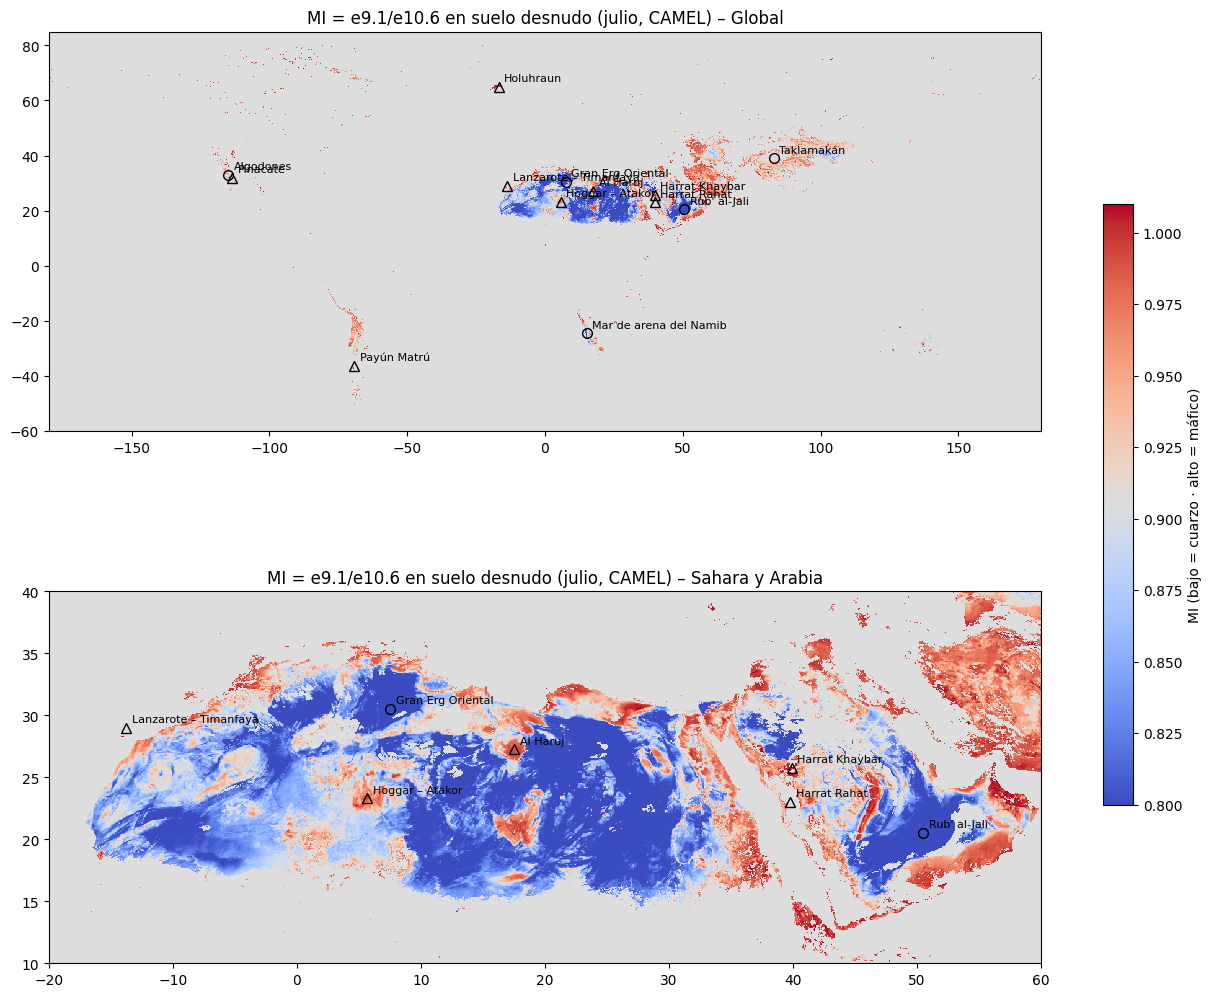

In [14]:
# ===== Índices de emisividad a 0.05° + máscara de suelo desnudo (VIIRS) =====
UMBRAL_DESNUDO = 0.15
FORZAR = False
ruta_luna = f"{PROCESADOS}/emisividad_indices_camel_07.nc"
ENC_LUNA = {v: {"dtype": "int16", "scale_factor": 1e-4, "_FillValue": -32768, "zlib": True}
            for v in ("MI", "QI", "CI", "nieve")}

if existe(ruta_luna, FORZAR):
    luna = xr.open_dataset(ruta_luna).load()
else:
    camel = xr.open_dataset(f"{BRUTOS}/CAM5K30EMCLIM_emis_climatology_07Month_V003.nc", engine="h5netcdf")
    wl = np.ravel(camel["wavelength"].values)
    k = {x: int(np.abs(wl - x).argmin()) for x in (8.3, 8.6, 9.1, 10.6, 11.3)}
    banda = lambda x: camel["camel_emis"].isel(spectra=k[x]).astype("float32").load()
    e83, e86, e91, e106, e113 = (banda(x) for x in (8.3, 8.6, 9.1, 10.6, 11.3))
    luna = xr.Dataset({"MI": e91 / e106,                     # bajo = mucho cuarzo; alto = máfico (o vegetación/agua)
                       "QI": e86**2 / (e83 * e91),           # alto = cuarzo
                       "CI": e106 / e113,                    # alto = carbonatos
                       "nieve": camel["snow_fraction_average"].astype("float32").load()})
    luna = luna.rename({"latitude": "lat", "longitude": "lon"}).sortby("lat")
    luna.attrs = {"fuente": "CAMEL climatología julio 2003-2021 (CAM5K30EMCLIM v003)",
                  "MI": "e9.1/e10.6", "QI": "e8.6^2/(e8.3*e9.1)", "CI": "e10.6/e11.3"}
    guardar_nc(luna, ruta_luna, ENC_LUNA)

# NDVI máximo a 0.05° (misma rejilla CMG)
nd = xr.open_dataarray(f"{PROCESADOS}/ndvi_max_2023_005.nc").load()
mismo_tamano = nd.sizes["lat"] == luna.sizes["lat"] and nd.sizes["lon"] == luna.sizes["lon"]
dlat = np.abs(nd.lat.values - luna.lat.values).max() if mismo_tamano else np.inf
dlon = np.abs(nd.lon.values - luna.lon.values).max() if mismo_tamano else np.inf
print(f"VIIRS : lat {nd.lat.values[0]:.4f} … {nd.lat.values[-1]:.4f} ({nd.sizes['lat']}) | "
      f"lon {nd.lon.values[0]:.4f} … {nd.lon.values[-1]:.4f} ({nd.sizes['lon']})")
print(f"CAMEL : lat {luna.lat.values[0]:.4f} … {luna.lat.values[-1]:.4f} ({luna.sizes['lat']}) | "
      f"lon {luna.lon.values[0]:.4f} … {luna.lon.values[-1]:.4f} ({luna.sizes['lon']})")
print(f"Diferencia máxima: lat {dlat:.4f}°, lon {dlon:.4f}°")

if dlat <= 0.026 and dlon <= 0.026:
    # Mismas celdas; solo cambia si la coordenada marca el centro o la esquina
    nd = nd.assign_coords(lat=luna.lat.values, lon=luna.lon.values)
    print("✔ misma rejilla: uso las coordenadas de CAMEL (centros de celda)")
else:
    nd = nd.sel(lat=luna.lat, lon=luna.lon, method="nearest")
    print("⚠ rejillas distintas: el NDVI se asigna al píxel más cercano de CAMEL")
desnudo = ((nd.values > -0.02) & (nd.values < UMBRAL_DESNUDO)        # fuera agua (NDVI<0) y vegetación
           & (np.nan_to_num(luna.nieve.values, nan=1) < 0.1)          # fuera nieve/hielo
           & ~np.isnan(luna.MI.values))
mi_desnudo = luna.MI.values[desnudo]
print(f"Celdas de 5 km con suelo desnudo: {desnudo.sum():,} | MI: p5 {np.percentile(mi_desnudo, 5):.3f} · "
      f"mediana {np.median(mi_desnudo):.3f} · p95 {np.percentile(mi_desnudo, 95):.3f}")

# Prueba a ciegas: campos volcánicos frente a mares de arena (coordenadas aproximadas)
PRUEBA = {
    "Al Haruj, Libia (campo basáltico)":         (27.25, 17.50, "volcánico"),
    "Harrat Khaybar, Arabia Saudí (basalto)":    (25.75, 39.90, "volcánico"),
    "Harrat Rahat, Arabia Saudí (basalto)":      (23.00, 39.80, "volcánico"),
    "Hoggar – Atakor, Argelia (basalto)":        (23.30, 5.65, "volcánico"),
    "Pinacate, México (basalto)":                (31.77, -113.50, "volcánico"),
    "Payún Matrú, Argentina (basalto)":          (-36.42, -69.24, "volcánico"),
    "Holuhraun, Islandia (basalto)":             (64.85, -16.83, "volcánico"),
    "Lanzarote – Timanfaya (basalto)":           (29.00, -13.75, "volcánico"),
    "Gran Erg Oriental (arena)":                 (30.50, 7.50, "arena"),
    "Rub' al-Jali (arena)":                      (20.50, 50.50, "arena"),
    "Taklamakán (arena)":                        (39.00, 83.00, "arena"),
    "Mar de arena del Namib (arena)":            (-24.50, 15.20, "arena"),
    "Algodones (arena)":                         (32.95, -115.05, "arena"),
}
filas = []
for nom, (la, lo, tipo) in PRUEBA.items():
    i, j = int(np.abs(luna.lat.values - la).argmin()), int(np.abs(luna.lon.values - lo).argmin())
    mi = float(luna.MI.values[i, j])
    filas.append({"punto": nom, "tipo": tipo, "desnudo": bool(desnudo[i, j]), "NDVI": round(float(nd.values[i, j]), 3),
                  "MI": round(mi, 3), "QI": round(float(luna.QI.values[i, j]), 3), "CI": round(float(luna.CI.values[i, j]), 3),
                  "percentil_MI_en_desnudo": round((mi_desnudo < mi).mean() * 100, 1)})
prueba_luna = pd.DataFrame(filas)
prueba_luna.to_csv(f"{PROCESADOS}/prueba_luna_emisividad.csv", index=False)
display(prueba_luna)
print("Mediana del percentil MI → volcánicos:",
      prueba_luna[prueba_luna.tipo == "volcánico"].percentil_MI_en_desnudo.median(),
      "| arenas:", prueba_luna[prueba_luna.tipo == "arena"].percentil_MI_en_desnudo.median())

# Mapas: MI solo en suelo desnudo (rojo = poco cuarzo / máfico; azul = cuarzo)
mi_mapa = np.where(desnudo, luna.MI.values, np.nan)
fig, axes = plt.subplots(2, 1, figsize=(16, 13))
for ax, (x0, x1, y0, y1, titulo) in zip(axes, [(-180, 180, -60, 85, "Global"),
                                               (-20, 60, 10, 40, "Sahara y Arabia")]):
    j0, j1 = np.searchsorted(luna.lon.values, [x0, x1]); i0, i1 = np.searchsorted(luna.lat.values, [y0, y1])
    im = ax.imshow(mi_mapa[i0:i1, j0:j1], origin="lower", extent=[x0, x1, y0, y1],
                   cmap="coolwarm", vmin=0.80, vmax=1.01, interpolation="nearest")
    for nom, (la, lo, tipo) in PRUEBA.items():
        if x0 <= lo <= x1 and y0 <= la <= y1:
            ax.plot(lo, la, "k^" if tipo == "volcánico" else "ko", ms=7, mfc="none")
            ax.annotate(nom.split(" (")[0].split(",")[0], (lo, la), fontsize=8, xytext=(4, 4), textcoords="offset points")
    ax.set_title(f"MI = e9.1/e10.6 en suelo desnudo (julio, CAMEL) – {titulo}"); ax.set_facecolor("#dddddd")
plt.colorbar(im, ax=axes, label="MI (bajo = cuarzo · alto = máfico)", shrink=0.6)
plt.show()

In [5]:
# ===== 1) ¿El NDVI alto de algunos basaltos es vegetación real o efecto de la superficie oscura? =====
PUNTOS_NDVI = {"Harrat Rahat": (23.00, 39.80), "Pinacate": (31.77, -113.50),
               "Lanzarote – Timanfaya": (29.00, -13.75), "Payún Matrú": (-36.42, -69.24),
               "Al Haruj (comparación)": (27.25, 17.50), "Atacama (suelo desnudo)": (-24.10, -70.00)}
series = {}
for nom, (la, lo) in PUNTOS_NDVI.items():
    serie = []
    for m in range(1, 13):
        with xr.open_dataarray(f"{BRUTOS}/ndvi_2023_{m:02d}.nc") as da:
            serie.append(round(float(da.sel(lat=la, lon=lo, method="nearest")), 2))
    series[nom] = serie
print("NDVI mensual 2023 (VIIRS, 5 km):")
display(pd.DataFrame(series, index=range(1, 13)).T)

# ===== 2) Verano de cada hemisferio: julio en el norte, enero en el sur =====
def indices_camel(mes):
    ruta_out = f"{PROCESADOS}/emisividad_indices_camel_{mes:02d}.nc"
    if existe(ruta_out):
        return xr.open_dataset(ruta_out).load()
    c = xr.open_dataset(descargar_camel(mes), engine="h5netcdf")
    wl = np.ravel(c["wavelength"].values)
    banda = lambda x: c["camel_emis"].isel(spectra=int(np.abs(wl - x).argmin())).astype("float32").load()
    e83, e86, e91, e106, e113 = (banda(x) for x in (8.3, 8.6, 9.1, 10.6, 11.3))
    out = xr.Dataset({"MI": e91 / e106, "QI": e86**2 / (e83 * e91), "CI": e106 / e113,
                      "nieve": c["snow_fraction_average"].astype("float32").load()})
    out = out.rename({"latitude": "lat", "longitude": "lon"}).sortby("lat")
    out.attrs = {"fuente": f"CAMEL climatología mes {mes:02d}, 2003-2021 (CAM5K30EMCLIM v003)"}
    guardar_nc(out, ruta_out, ENC_LUNA)
    return out

luna_jul, luna_ene = indices_camel(7), indices_camel(1)
sur = luna_jul.lat < 0
luna_v = xr.Dataset({v: xr.where(sur, luna_ene[v], luna_jul[v]) for v in ("MI", "QI", "CI", "nieve")})
luna_v.attrs = {"fuente": "CAMEL climatología 2003-2021: julio al norte del ecuador, enero al sur",
                "MI": "e9.1/e10.6", "QI": "e8.6^2/(e8.3*e9.1)", "CI": "e10.6/e11.3"}
guardar_nc(luna_v, f"{PROCESADOS}/emisividad_indices_camel_verano.nc", ENC_LUNA)

desnudo = ((nd.values > -0.02) & (nd.values < UMBRAL_DESNUDO)
           & (np.nan_to_num(luna_v.nieve.values, nan=1) < 0.1) & ~np.isnan(luna_v.MI.values))
mi_desnudo = luna_v.MI.values[desnudo]
filas = []
for nom, (la, lo, tipo) in PRUEBA.items():
    i, j = int(np.abs(luna_v.lat.values - la).argmin()), int(np.abs(luna_v.lon.values - lo).argmin())
    mi = float(luna_v.MI.values[i, j])
    filas.append({"punto": nom, "tipo": tipo, "desnudo": bool(desnudo[i, j]),
                  "nieve": round(float(luna_v.nieve.values[i, j]), 2), "MI": round(mi, 3),
                  "CI": round(float(luna_v.CI.values[i, j]), 3),
                  "percentil_MI_en_desnudo": round((mi_desnudo < mi).mean() * 100, 1)})
print(f"\nVerano de cada hemisferio | celdas desnudas: {desnudo.sum():,}")
display(pd.DataFrame(filas))

# ===== 3) ¿Qué hay en las zonas de MI alto que no son volcánicas? Índice de carbonatos (CI) =====
p90 = np.percentile(mi_desnudo, 90)
alto_mi = desnudo & (luna_v.MI.values >= p90)
ci_alto = luna_v.CI.values[alto_mi]
ci_volc = [f["CI"] for f in filas if f["tipo"] == "volcánico"]
print(f"\nCeldas desnudas con MI ≥ p90 ({p90:.3f}): {alto_mi.sum():,}")
print("CI en esas celdas: p10 {:.3f} · mediana {:.3f} · p90 {:.3f} | CI en los 8 volcánicos: {:.3f}–{:.3f}"
      .format(*np.percentile(ci_alto, [10, 50, 90]), min(ci_volc), max(ci_volc)))

ci_mapa = np.where(alto_mi, luna_v.CI.values, np.nan)
x0, x1, y0, y1 = -20, 70, 10, 45
j0, j1 = np.searchsorted(luna_v.lon.values, [x0, x1]); i0, i1 = np.searchsorted(luna_v.lat.values, [y0, y1])
fig, ax = plt.subplots(figsize=(16, 8))
im = ax.imshow(ci_mapa[i0:i1, j0:j1], origin="lower", extent=[x0, x1, y0, y1],
               cmap="PiYG_r", vmin=0.98, vmax=1.03, interpolation="nearest")
for nom, (la, lo, tipo) in PRUEBA.items():
    if x0 <= lo <= x1 and y0 <= la <= y1 and tipo == "volcánico":
        ax.plot(lo, la, "k^", ms=8, mfc="none")
        ax.annotate(nom.split(" (")[0].split(",")[0], (lo, la), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.set_facecolor("#dddddd")
ax.set_title("Celdas desnudas con MI ≥ p90, coloreadas por CI = e10.6/e11.3 (rosa = posible carbonato)")
plt.colorbar(im, ax=ax, label="CI", shrink=0.7); plt.show()

NDVI mensual 2023 (VIIRS, 5 km):


,1,2,3,4,5,6,7,8,9,10,11,12
Harrat Rahat,0.29,0.26,0.18,0.13,0.12,0.11,0.10,0.10,0.10,0.10,0.14,0.19
Pinacate,0.18,0.18,0.19,0.16,0.15,0.14,0.14,0.14,0.16,0.16,0.15,0.15
Lanzarote – Timanfaya,0.15,0.15,0.14,0.13,0.11,0.12,0.12,0.10,0.11,0.12,0.12,0.11
Payún Matrú,0.07,0.07,0.07,0.07,0.03,0.03,-0.03,-0.03,-0.03,-0.01,0.01,0.07
Al Haruj (comparación),0.10,0.10,0.10,0.09,0.09,0.09,0.09,0.09,0.09,0.10,0.10,0.10
Atacama (suelo desnudo),0.10,0.10,0.10,0.10,0.10,0.10,0.10,0.10,0.10,0.10,0.10,0.10


NameError: name 'existe' is not defined

In [4]:
# ===== NDVI mediano anual 2023 (para el perfil Luna) =====
ENC = {"ndvi": {"dtype": "int16", "scale_factor": 1e-4, "_FillValue": -32768, "zlib": True}}
ruta_med = f"{PROCESADOS}/ndvi_mediana_2023_005.nc"
if existe(ruta_med):
    ndvi_med = xr.open_dataarray(ruta_med).load()
else:
    meses = [xr.open_dataarray(f"{BRUTOS}/ndvi_2023_{m:02d}.nc") for m in range(1, 13)]
    med = np.full(meses[0].shape, np.nan, dtype="float32")
    for i0 in range(0, med.shape[0], 600):                       # por bandas de latitud, para no agotar la RAM
        pila = np.stack([m.values[i0:i0 + 600].astype("float32") for m in meses])
        med[i0:i0 + 600] = np.nanmedian(pila, axis=0)
    ndvi_med = xr.DataArray(med, dims=("lat", "lon"), coords={"lat": meses[0].lat, "lon": meses[0].lon}, name="ndvi")
    ndvi_med.attrs = {"long_name": "NDVI mediano mensual 2023 (VIIRS VNP13C2 v002, 0.05°)"}
    guardar_nc(ndvi_med.to_dataset(), ruta_med, ENC)
ndvi_med = ndvi_med.assign_coords(lat=luna_v.lat.values, lon=luna_v.lon.values)   # misma rejilla, centros de celda

sin_nieve = np.nan_to_num(luna_v.nieve.values, nan=1) < 0.1
con_mi = ~np.isnan(luna_v.MI.values)
desnudo_max = (nd.values > -0.02) & (nd.values < UMBRAL_DESNUDO) & sin_nieve & con_mi
desnudo_med = (ndvi_med.values > -0.02) & (ndvi_med.values < UMBRAL_DESNUDO) & sin_nieve & con_mi
print(f"Celdas desnudas → con NDVI máximo: {desnudo_max.sum():,} | con NDVI mediano: {desnudo_med.sum():,}")

filas = []
for nom, (la, lo, tipo) in PRUEBA.items():
    i, j = int(np.abs(luna_v.lat.values - la).argmin()), int(np.abs(luna_v.lon.values - lo).argmin())
    filas.append({"punto": nom, "tipo": tipo, "NDVI_max": round(float(nd.values[i, j]), 3),
                  "NDVI_mediana": round(float(ndvi_med.values[i, j]), 3),
                  "nieve": round(float(luna_v.nieve.values[i, j]), 3), "MI_es_nan": bool(np.isnan(luna_v.MI.values[i, j])),
                  "desnudo_max": bool(desnudo_max[i, j]), "desnudo_mediana": bool(desnudo_med[i, j])})
display(pd.DataFrame(filas))

NameError: name 'existe' is not defined